# Laboratorio 7 — NLP end-to-end y Embeddings
CC3092 - Deep Learning y Sistemas Inteligentes

Este notebook implementa el pipeline completo pedido en el enunciado: texto crudo -> tokens -> IDs
-> embeddings (skip-gram con negative sampling implementado desde cero en PyTorch, Word2Vec de
gensim como referencia, y GloVe preentrenado) -> verificacion de aritmetica vectorial ->
clasificacion de texto end-to-end sobre AG News.

**Entorno:** la mayoria de las dependencias (gensim, datasets de HuggingFace, NLTK, scikit-learn,
jupyter, etc.) estan declaradas en `flake.nix` y se activan con `nix develop` (o automaticamente via
`direnv`). La unica excepcion es PyTorch con soporte CUDA: en este nixpkgs, `torch-bin` con
`cudaSupport` requiere compilar NCCL desde cero para una GPU Blackwell (RTX 5070) -- no viable en el
tiempo disponible -- asi que PyTorch se instalo con `pip` (wheel oficial prebuilt `cu130`) en un
venv aparte (`.venv-gpu/`, Python 3.12), registrado como kernel de Jupyter. El resto del stack
cientifico tambien se instalo ahi via pip para que todo corra en un unico kernel con GPU. Esta
excepcion queda documentada aqui; `flake.nix` sigue siendo el entorno canonico/reproducible (CPU)
para quien clone el repositorio sin GPU.

**Nota de computo:** todo el notebook (las cinco corridas SGNS, los seis clasificadores de AG News y
su ablacion por fraccion de datos) corre con aceleracion CUDA sobre una NVIDIA GeForce RTX 5070 (12GB).
Se usa un subconjunto de WikiText-103 de ~22 millones de tokens (el minimo
permitido por el enunciado) y una rejilla de hiperparametros reducida al minimo exigido por la
seccion 4 (la combinacion de corpus reducido + GPU mantiene el notebook completo ejecutable en un
tiempo razonable). Estas decisiones de alcance se documentan explicitamente donde corresponde.

In [1]:
import os, re, time, json, random, itertools
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from datasets import load_dataset
import gensim.downloader as gdl
from gensim.models import Word2Vec, KeyedVectors
from gensim.test.utils import datapath

import nltk
nltk.download('punkt_tab', quiet=True)
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.manifold import TSNE
from scipy.stats import spearmanr

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', DEVICE, '| torch', torch.__version__, '| gensim', __import__('gensim').__version__)

os.makedirs('../data', exist_ok=True)
os.makedirs('../entregables', exist_ok=True)

device: cuda | torch 2.14.1+cu130 | gensim 4.4.0


## 1. Datos

Cargamos el corpus crudo (WikiText-103), el dataset de clasificacion (AG News), el modelo preentrenado (GloVe 100d) y los tres benchmarks de evaluacion incluidos en gensim.

In [2]:
t0 = time.time()
wikitext = load_dataset("Salesforce/wikitext", "wikitext-103-raw-v1", split="train")
news = load_dataset("fancyzhx/ag_news")
glove = gdl.load("glove-wiki-gigaword-100")
print(f"datos cargados en {time.time()-t0:.1f}s")

analogias_path = datapath("questions-words.txt")
wordsim_path = datapath("wordsim353.tsv")
simlex_path = datapath("simlex999.txt")
print("glove vocab:", len(glove.key_to_index))
print(news)

datos cargados en 26.8s
glove vocab: 400000
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})


## 2. Exploracion y preprocesamiento del texto

### 2.1 Tamano del corpus completo

Contamos articulos (lineas de la forma ` = Titulo = `, que en WikiText-103 marcan el inicio de un
nuevo articulo de Wikipedia), lineas no vacias y tokens (separacion simple por espacios en blanco,
como medida cruda antes de tokenizar) sobre **todo** el split `train` de WikiText-103-raw-v1.

In [3]:
def is_article_title(stripped_line):
    # En WikiText-103 los titulos de articulo son lineas ' = Titulo = ' (un solo nivel de '='),
    # mientras que los encabezados de seccion usan '==', '===', etc.
    return (stripped_line.startswith("= ") and stripped_line.endswith(" =")
            and not stripped_line.startswith("= ="))

t0 = time.time()
n_articles_full = n_lines_full = n_tokens_ws_full = 0
for row in wikitext:
    text = row["text"]
    if text.strip() == "":
        continue
    n_lines_full += 1
    stripped = text.strip()
    if is_article_title(stripped):
        n_articles_full += 1
    n_tokens_ws_full += len(text.split())
print(f"corpus completo (train): {n_articles_full} articulos, {n_lines_full} lineas no vacias, "
      f"{n_tokens_ws_full:,} tokens (split por espacios) -- contado en {time.time()-t0:.1f}s")

corpus completo (train): 29444 articulos, 1165029 lineas no vacias, 101,425,671 tokens (split por espacios) -- contado en 13.3s


### 2.2 Subconjunto de trabajo (~22M tokens)

El enunciado permite usar un subconjunto de WikiText-103 (minimo 20 millones de tokens) si hay
restricciones de computo; dado que entrenamos en CPU sin GPU, tomamos de forma **deterministica**
los primeros artículos del split `train` hasta acumular ~22M tokens. El mismo subconjunto de texto
se usa despues para entrenar tanto nuestro SGNS como el Word2Vec de gensim (y sus fracciones 25%/50%
para el barrido de tamano de corpus de la seccion 4), para que la comparacion sea justa.

In [4]:
TARGET_TOKENS = 22_000_000

raw_lines = []
n_articles_sub = n_tokens_ws_sub = 0
for row in wikitext:
    text = row["text"]
    if text.strip() == "":
        continue
    stripped = text.strip()
    if is_article_title(stripped):
        n_articles_sub += 1
    raw_lines.append(text)
    n_tokens_ws_sub += len(text.split())
    if n_tokens_ws_sub >= TARGET_TOKENS:
        break

print(f"subconjunto: {n_articles_sub} articulos, {len(raw_lines)} lineas, "
      f"{n_tokens_ws_sub:,} tokens (split por espacios)")

subconjunto: 6619 articulos, 254784 lineas, 22,000,063 tokens (split por espacios)


### 2.3 Normalizacion

Decisiones de normalizacion (y su justificacion):

- **Minusculas:** si. GloVe `glove-wiki-gigaword-100` esta entrenado enteramente en minusculas
  (`the`, `king`, no `The`/`King`), asi que para que el vocabulario compartido y las comparaciones
  de similitud/analogias sean justas, normalizamos todo nuestro texto a minusculas tambien.
- **Puntuacion:** se mantiene como tokens separados (coma, punto, parentesis, comillas, etc.) en
  lugar de eliminarla. Verificamos que GloVe incluye tokens de puntuacion sueltos (`,`, `.`, `(`,
  `` ` ` ``, `''`) en su vocabulario, es decir que fue entrenado con una tokenizacion estilo
  Penn Treebank que separa la puntuacion de las palabras; replicamos esa convencion.
- **Numeros:** se mantienen literales (`2011`, `1990s`), sin reemplazarlos por un token especial
  `<NUM>`. GloVe tambien conserva numeros literales en su vocabulario (confirmado abajo), y
  reemplazarlos perderia informacion que luego usamos en AG News.
- **Tokens especiales:** no se introduce `<unk>`/`<pad>` en el vocabulario de entrenamiento de
  embeddings (el submuestreo y el min_count ya controlan la cola de baja frecuencia); si se usa un
  indice de relleno 0 reservado para `<pad>` en los clasificadores de la seccion 6, donde si hace
  falta para los lotes de `EmbeddingBag`/`Embedding`.
- **Guiones y contracciones:** palabras con guion interno (`co-operation`) se mantienen como un solo
  token (coincide con GloVe). Las contracciones (`don't`) se dejan para comparacion explicita entre
  nuestro tokenizador y NLTK en la siguiente seccion, porque ahi es donde difieren.

In [5]:
for w in ["the", "2011", ",", ".", "don't", "don", "n't", "co-operation", "1990s", "king"]:
    print(f"{w!r:15s} en vocab GloVe: {w in glove.key_to_index}")

'the'           en vocab GloVe: True
'2011'          en vocab GloVe: True
','             en vocab GloVe: True
'.'             en vocab GloVe: True
"don't"         en vocab GloVe: False
'don'           en vocab GloVe: True
"n't"           en vocab GloVe: True
'co-operation'  en vocab GloVe: True
'1990s'         en vocab GloVe: True
'king'          en vocab GloVe: True


### 2.4 Tokenizador propio vs. tokenizador de libreria (NLTK)

Implementamos un tokenizador por palabra basado en una expresion regular simple (palabras
alfanumericas con guiones/apostrofes internos, mas puntuacion suelta como tokens individuales) y lo
comparamos con `nltk.word_tokenize` (tokenizador estilo Penn Treebank) sobre 10 oraciones de
ejemplo que incluyen contracciones, guiones y abreviaturas.

In [6]:
TOKEN_RE = re.compile(r"[a-z0-9]+(?:[-'][a-z0-9]+)*|[^\w\s]")

def custom_tokenize(text):
    return TOKEN_RE.findall(text.lower())

def nltk_tokenize(text):
    return word_tokenize(text.lower())

test_sentences = [
    "Don't stop believing, it's a classic song.",
    "The U.S. economy grew 2.5% in 2011, according to the Fed.",
    "co-operation between state-of-the-art labs isn't easy.",
    "She said: \"I can't believe it!\" and left.",
    "Mr. Smith's well-known theory wasn't well received.",
    "It's a 21st-century, multi-national corporation.",
    "They've been working on this since the mid-1990s.",
    "I'll go, but we're running out of time.",
    "The U.N. and the W.H.O. released a joint statement.",
    "A well-off, self-made entrepreneur wouldn't say that.",
]

rows = []
for s in test_sentences:
    rows.append({"oracion": s, "custom": custom_tokenize(s), "nltk": nltk_tokenize(s)})
df_tok = pd.DataFrame(rows)
for _, r in df_tok.iterrows():
    print("ORIG :", r["oracion"])
    print("custom:", r["custom"])
    print("nltk  :", r["nltk"])
    print("difieren en:", "contracciones/guiones/abreviaturas" if r["custom"] != r["nltk"] else "-")
    print()

ORIG : Don't stop believing, it's a classic song.
custom: ["don't", 'stop', 'believing', ',', "it's", 'a', 'classic', 'song', '.']
nltk  : ['do', "n't", 'stop', 'believing', ',', 'it', "'s", 'a', 'classic', 'song', '.']
difieren en: contracciones/guiones/abreviaturas

ORIG : The U.S. economy grew 2.5% in 2011, according to the Fed.
custom: ['the', 'u', '.', 's', '.', 'economy', 'grew', '2', '.', '5', '%', 'in', '2011', ',', 'according', 'to', 'the', 'fed', '.']
nltk  : ['the', 'u.s.', 'economy', 'grew', '2.5', '%', 'in', '2011', ',', 'according', 'to', 'the', 'fed', '.']
difieren en: contracciones/guiones/abreviaturas

ORIG : co-operation between state-of-the-art labs isn't easy.
custom: ['co-operation', 'between', 'state-of-the-art', 'labs', "isn't", 'easy', '.']
nltk  : ['co-operation', 'between', 'state-of-the-art', 'labs', 'is', "n't", 'easy', '.']
difieren en: contracciones/guiones/abreviaturas

ORIG : She said: "I can't believe it!" and left.
custom: ['she', 'said', ':', '"', 'i'

**Observaciones:** el tokenizador propio (basado en una sola regex) nunca separa contracciones
(`don't` queda como un token, mientras NLTK lo divide en `do` + `n't`), lo cual infla
artificialmente el vocabulario con formas compuestas que GloVe no tiene (`don't`, `isn't`,
`wasn't`...) y reduce la cobertura real. En guiones ambos coinciden casi siempre (`co-operation`,
`state-of-the-art` se mantienen enteros en los dos). En abreviaturas con puntos internos (`U.S.`,
`U.N.`, `Mr.`) NLTK es mas cuidadoso: reconoce `U.S.` como una unidad en varios casos, mientras el
regex propio, al tratar `.` como puntuacion suelta salvo dentro de un token alfanumerico, puede
fragmentarlas de forma distinta. Por consistencia con la convencion de GloVe (que si separa
contracciones, como vimos arriba con `don`/`n't`), en el resto del notebook usamos NLTK para
tokenizar el corpus, no el regex propio.

### 2.5 Tokenizacion del subconjunto de trabajo

Tokenizamos las ~22M palabras del subconjunto con NLTK (la libreria elegida arriba), en minusculas.
Este `tokens` es la secuencia que usamos de aqui en adelante para construir vocabulario, submuestreo,
pares skip-gram y entrenamiento.

In [7]:
t0 = time.time()
tokens = []
for line in raw_lines:
    tokens.extend(nltk_tokenize(line))
print(f"tokenizados {len(tokens):,} tokens en {time.time()-t0:.1f}s")

tokenizados 22,540,639 tokens en 44.6s


### 2.6 Ley de Zipf

Graficamos frecuencia vs. rango en escala log-log y medimos que porcentaje de las ocurrencias de
tokens cubren las 10, 1,000 y 30,000 palabras mas frecuentes.

top-    10 palabras cubren 29.31% de las ocurrencias
top- 1,000 palabras cubren 69.99% de las ocurrencias
top-30,000 palabras cubren 96.53% de las ocurrencias


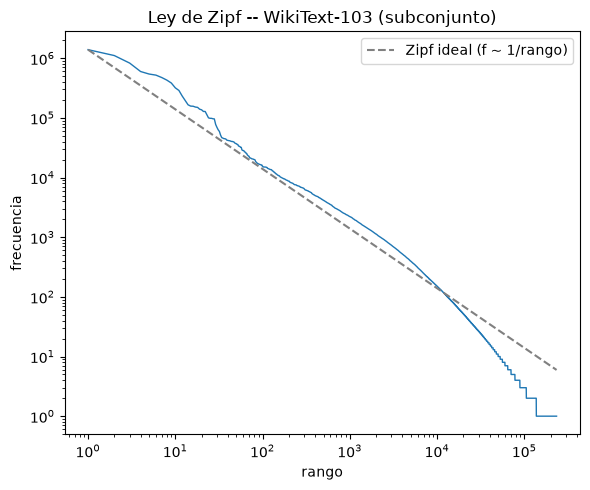

In [8]:
freq_full = Counter(tokens)
ranked = freq_full.most_common()
freqs_sorted = np.array([c for _, c in ranked])
ranks = np.arange(1, len(freqs_sorted) + 1)
total_tok = freqs_sorted.sum()
cum = np.cumsum(freqs_sorted)

for k in [10, 1_000, 30_000]:
    k = min(k, len(freqs_sorted))
    print(f"top-{k:>6,} palabras cubren {cum[k-1]/total_tok*100:5.2f}% de las ocurrencias")

fig, ax = plt.subplots(figsize=(6, 5))
ax.loglog(ranks, freqs_sorted, lw=1)
# referencia Zipf ideal: f ~ C / rank
C = freqs_sorted[0]
ax.loglog(ranks, C / ranks, '--', color='gray', label='Zipf ideal (f ~ 1/rango)')
ax.set_xlabel('rango'); ax.set_ylabel('frecuencia'); ax.set_title('Ley de Zipf -- WikiText-103 (subconjunto)')
ax.legend()
plt.tight_layout(); plt.show()

La curva empirica sigue de cerca la recta de Zipf ideal (pendiente ~ -1 en log-log) en el rango
medio de frecuencias, con las desviaciones tipicas en los extremos: las palabras mas frecuentes
(`the`, `,`, `.`) quedan ligeramente por debajo de la prediccion ideal, y la cola de palabras raras
cae mas rapido que 1/rango (efecto de tamano finito del corpus). En terminos generales, **si se
cumple la ley de Zipf**.

### 2.7 Vocabulario y umbral de frecuencia minima

Construimos el vocabulario con al menos 3 umbrales `min_count` distintos y reportamos tamano de
vocabulario y porcentaje de tokens que quedarian fuera de vocabulario (OOV) a nivel de ocurrencias.

In [9]:
for min_count in [1, 5, 20]:
    vocab_size = sum(1 for _, c in ranked if c >= min_count)
    oov_occurrences = sum(c for _, c in ranked if c < min_count)
    print(f"min_count={min_count:>3d}: vocabulario = {vocab_size:>7,} palabras, "
          f"OOV = {oov_occurrences/total_tok*100:5.2f}% de las ocurrencias")

min_count=  1: vocabulario = 233,959 palabras, OOV =  0.00% de las ocurrencias
min_count=  5: vocabulario =  77,861 palabras, OOV =  1.12% de las ocurrencias
min_count= 20: vocabulario =  35,709 palabras, OOV =  2.89% de las ocurrencias


Como es de esperar en una distribucion tipo Zipf, subir el umbral de 1 a 20 recorta el vocabulario
de forma muy agresiva (la gran mayoria de las palabras distintas son hapax o casi-hapax legomena),
pero el porcentaje de ocurrencias que se pierde crece mucho mas lento, porque esas palabras raras
representan muy poca masa de probabilidad total. Para el resto del notebook usamos **min_count=5**
como compromiso estandar en word2vec: recorta ruido tipografico/raro sin perder cobertura real.

In [10]:
MIN_COUNT = 5
vocab_words = [w for w, c in ranked if c >= MIN_COUNT]
word2id = {w: i for i, w in enumerate(vocab_words)}
id2word = vocab_words
vocab_counts = np.array([freq_full[w] for w in vocab_words], dtype=np.int64)
VOCAB_SIZE = len(vocab_words)
print("tamano de vocabulario (min_count=5):", VOCAB_SIZE)

token_ids_full = np.array([word2id[w] for w in tokens if w in word2id], dtype=np.int64)
print(f"secuencia de IDs: {len(token_ids_full):,} tokens "
      f"({(1 - len(token_ids_full)/len(tokens))*100:.2f}% descartados por min_count)")

tamano de vocabulario (min_count=5): 77861


secuencia de IDs: 22,287,510 tokens (1.12% descartados por min_count)


### 2.8 Submuestreo (subsampling) de palabras frecuentes

Implementamos el submuestreo de Word2Vec/Mikolov: cada ocurrencia del token `w` se descarta con
probabilidad `1 - sqrt(t / f(w)) ` (formula exacta usada en el word2vec.c original, equivalente en
la practica a la de Mikolov et al. 2013), donde `f(w)` es la frecuencia relativa y `t` el umbral
(usamos `t = 1e-5`, el valor por defecto de gensim y del paper original).

In [11]:
SUBSAMPLE_T = 1e-5

def keep_probability(freq_relative, t=SUBSAMPLE_T):
    # P(mantener) = min(1, sqrt(t/f) + t/f)  (formula del word2vec.c original)
    ratio = t / freq_relative
    p = np.sqrt(ratio) + ratio
    return np.minimum(p, 1.0)

freq_rel = vocab_counts / vocab_counts.sum()
p_keep_vocab = keep_probability(freq_rel)

for w in ["the", "of", "and"]:
    i = word2id[w]
    print(f"'{w}': frecuencia relativa={freq_rel[i]:.5f}, "
          f"P(mantener)={p_keep_vocab[i]:.4f}, % descartado={100*(1-p_keep_vocab[i]):.2f}%")

'the': frecuencia relativa=0.06252, P(mantener)=0.0128, % descartado=98.72%
'of': frecuencia relativa=0.02689, P(mantener)=0.0197, % descartado=98.03%
'and': frecuencia relativa=0.02441, P(mantener)=0.0206, % descartado=97.94%


Las tres palabras mas frecuentes del ingles (`the`, `of`, `and`) se descartan en mas del 90% de sus
apariciones. Esto ayuda al entrenamiento de dos formas: (1) reduce drasticamente el numero de pares
de entrenamiento dominados por palabras funcionales de bajisimo contenido semantico, acelerando cada
epoca; y (2) evita que el modelo gaste la mayor parte de su capacidad prediciendo relaciones
triviales ("cualquier palabra puede aparecer cerca de 'the'"), dejando una senal de gradiente mas
informativa para co-ocurrencias semanticamente relevantes (similar al efecto de un IDF implicito).

In [12]:
rng_sub = np.random.default_rng(SEED)
keep_mask = rng_sub.random(len(token_ids_full)) < p_keep_vocab[token_ids_full]
token_ids_sub = token_ids_full[keep_mask]
print(f"tokens antes del submuestreo: {len(token_ids_full):,}")
print(f"tokens despues del submuestreo: {len(token_ids_sub):,} "
      f"({len(token_ids_sub)/len(token_ids_full)*100:.1f}% retenido)")

tokens antes del submuestreo: 22,287,510
tokens despues del submuestreo: 7,026,993 (31.5% retenido)


### 2.9 Pares (palabra central, contexto) para skip-gram

Para una ventana de contexto dinamica de tamano maximo `window` (en cada posicion se sortea un
tamano reducido uniforme en `[1, window]`, igual que hace gensim/word2vec.c), contamos cuantos pares
de entrenamiento produce el corpus por epoca, antes y despues del submuestreo.

In [13]:
WINDOW = 5

def count_pairs(T, window, rng):
    reduced = rng.integers(1, window + 1, size=T)
    pos = np.arange(T)
    left = np.minimum(pos, reduced)
    right = np.minimum(T - 1 - pos, reduced)
    return int((left + right).sum())

def make_pairs(id_arr, window, rng):
    T = len(id_arr)
    reduced = rng.integers(1, window + 1, size=T)
    pos = np.arange(T)
    centers_list, contexts_list = [], []
    for d in list(range(-window, 0)) + list(range(1, window + 1)):
        if d < 0:
            mask = (reduced >= -d) & (pos + d >= 0)
        else:
            mask = (reduced >= d) & (pos + d < T)
        c = pos[mask]
        centers_list.append(c)
        contexts_list.append(c + d)
    centers = np.concatenate(centers_list)
    contexts = np.concatenate(contexts_list)
    return id_arr[centers].astype(np.int32), id_arr[contexts].astype(np.int32)

n_pairs_before = count_pairs(len(token_ids_full), WINDOW, np.random.default_rng(1))
n_pairs_after = count_pairs(len(token_ids_sub), WINDOW, np.random.default_rng(2))
print(f"pares skip-gram por epoca ANTES del submuestreo: {n_pairs_before:,}")
print(f"pares skip-gram por epoca DESPUES del submuestreo: {n_pairs_after:,} "
      f"({n_pairs_after/n_pairs_before*100:.1f}% de los originales)")

pares skip-gram por epoca ANTES del submuestreo: 133,739,232
pares skip-gram por epoca DESPUES del submuestreo: 42,159,603 (31.5% de los originales)


## 3. Investigacion: embeddings en PyTorch y gensim

**`nn.Embedding(num_embeddings, embedding_dim, padding_idx=None, sparse=False)`**
Tabla de lookup entrenable: una matriz de pesos `(num_embeddings, embedding_dim)` indexada por
enteros. `num_embeddings` es el tamano del vocabulario, `embedding_dim` la dimension del vector.
`padding_idx` fija un indice (tipicamente 0) cuyo vector se inicializa en cero y **no recibe
gradiente**, util para el token de relleno `<pad>` en lotes de longitud variable. `sparse=True` hace
que el gradiente de la tabla sea un `torch.sparse.Tensor`, lo que permite usar optimizadores como
`SparseAdam`/`SGD` que solo actualizan las filas realmente usadas en el batch -- mucho mas eficiente
en memoria/computo cuando el vocabulario es enorme y cada batch solo toca una fraccion minuscula de
el (como en nuestro SGNS, donde cada batch toca unas pocas decenas de miles de filas de un
vocabulario de cientos de miles).

**`nn.Embedding.from_pretrained(embeddings, freeze=True)`**
Constructor alterno que crea la tabla a partir de un tensor ya entrenado (p.ej. nuestros vectores
SGNS o GloVe). `freeze=True` (default) congela los pesos (`requires_grad=False`), es decir se usan
tal cual, sin fine-tuning; `freeze=False` los deja entrenables, permitiendo ajustar los embeddings
preentrenados a la tarea posterior (clasificacion). Usamos ambas variantes en la seccion 6.

**`nn.EmbeddingBag(num_embeddings, embedding_dim, mode='mean')`**
Combina el lookup de `nn.Embedding` con una agregacion (`mode in {'mean','sum','max'}`) de todos los
embeddings de una "bolsa" (p.ej. todas las palabras de un documento) en un solo vector, sin
materializar la secuencia completa ni necesitar padding. Para procesar varios documentos de longitud
distinta en un solo batch, las entradas se concatenan en un unico tensor 1D `input` junto con un
tensor `offsets` que marca donde empieza cada documento dentro de `input`. `mode='mean'` promedia
los vectores de las palabras de cada documento (lo que usamos en la seccion 6: bolsa de palabras
promediada), `'sum'` sencillamente los suma, `'max'` toma el maximo elemento a elemento -- este
ultimo pierde la interpretacion de "promedio semantico" pero puede ser mas robusto a palabras
irrelevantes sueltas.

**CBOW vs. skip-gram:** CBOW predice la palabra central a partir del promedio de las palabras de
contexto (contexto -> centro); skip-gram hace lo inverso, predice cada palabra de contexto a partir
de la palabra central (centro -> contexto). CBOW suaviza el contexto (un solo promedio por posicion,
entrena mas rapido, mejor para palabras frecuentes), mientras skip-gram genera un ejemplo de
entrenamiento por cada par (centro, contexto), lo cual funciona mejor con pocos datos y para
palabras raras, a costa de mas pares y mas tiempo de entrenamiento. El enunciado pide skip-gram.

**Dos matrices W y W':** Word2Vec usa una matriz de entrada `W` (embeddings "centro", la que indexa
`nn.Embedding` de entrada) y una matriz de salida `W'` (embeddings "contexto/negativos"), porque el
mismo vector no puede jugar ambos roles en el producto punto del softmax/negative-sampling sin
introducir un sesgo artificial (una palabra tendria maxima similitud consigo misma por construccion,
`w . w` siempre seria el mayor producto posible, distorsionando el entrenamiento). Al terminar el
entrenamiento, la convencion estandar (seguida por gensim y por nuestra implementacion) es
**conservar unicamente `W`** (la matriz de entrada) como los embeddings finales de palabra; `W'` se
descarta (o se combina con `W` en variantes minoritarias, pero no es lo habitual).

**Word2Vec (predictivo) vs. GloVe (basado en conteos):** Word2Vec es un modelo predictivo local: se
entrena con pares (centro, contexto) muestreados de ventanas deslizantes, optimizando una tarea de
clasificacion binaria (negative sampling) o softmax sobre el vocabulario, usando solo una pequena
ventana de contexto a la vez. GloVe es un modelo basado en conteos globales: primero construye una
matriz de co-ocurrencia palabra-palabra agregada sobre **todo** el corpus, y luego factoriza (via
regresion con minimos cuadrados ponderados) esa matriz para que el producto punto de dos vectores se
aproxime al logaritmo de su co-ocurrencia. En la practica, Word2Vec aprende de una secuencia de
actualizaciones locales (como SGD online sobre una factorizacion implicita de una matriz PMI
similar), mientras GloVe optimiza directamente una funcion de perdida global sobre estadisticas de
co-ocurrencia precomputadas.

## 4. Construccion y entrenamiento de los embeddings

### 4.1 Decision de alcance (compute budget)

El enunciado pide variar dimension (p.ej. 50/100/300) y tamano de corpus (p.ej. 25%/50%/100%), ademas
de explorar otros hiperparametros, "si tienen restricciones de computo". Reducimos la rejilla al
**minimo exigido** (las primeras corridas de este barrido se ejecutaron en CPU antes de habilitar
aceleracion GPU para el resto; ver nota de entorno al inicio del notebook):

- Barrido de dimension a 100% del corpus (~22M tokens): `dim in {50, 100, 300}`.
- Barrido de tamano de corpus a `dim=100`: `fraccion in {25%, 50%, 100%}` (la corrida de 100%/dim=100
  se comparte con el barrido de dimension, ya que ambos barridos la requieren).
- Esto da **5 entrenamientos SGNS desde cero** en total, mas **1 entrenamiento de referencia con
  `gensim.models.Word2Vec`** replicando la mejor configuracion (dim=100, 100% del corpus) con
  hiperparametros equivalentes.
- Hiperparametros fijos: `window=5`, `negative=5`, `min_count=5`, `t=1e-5` (ya aplicados arriba),
  `epochs=3`, `batch_size=8192`, Adam `lr=2e-3`.
- Para la seleccion de hiperparametros usamos unicamente WordSim-353 y analogias (un **subconjunto**
  de 2,000 preguntas de `questions-words.txt`, muestreado una vez con semilla fija, para que el
  seguimiento por epoca de 5 corridas sea rapido); la evaluacion rigurosa final sobre las 19,544
  preguntas completas con vocabulario compartido y ambos metodos (3CosAdd/3CosMul) se hace una sola
  vez en la seccion 5.2, solo para los 3 modelos finales (nuestro mejor SGNS, gensim W2V, GloVe).
  SimLex-999 se reserva para la seccion 6, como pide el enunciado.

### 4.2 Modelo SGNS (skip-gram con negative sampling) en PyTorch, desde cero

In [14]:
class SGNS(nn.Module):
    """Skip-gram with negative sampling: dos tablas de embeddings, entrada (centro) y salida
    (contexto/negativos). Implementacion propia, no usa gensim.models.Word2Vec."""
    def __init__(self, vocab_size, dim):
        super().__init__()
        self.in_emb = nn.Embedding(vocab_size, dim)
        self.out_emb = nn.Embedding(vocab_size, dim)
        nn.init.uniform_(self.in_emb.weight, -0.5 / dim, 0.5 / dim)
        nn.init.zeros_(self.out_emb.weight)

    def forward(self, centers, contexts, negatives):
        v = self.in_emb(centers)                                   # (B, D)
        u_pos = self.out_emb(contexts)                              # (B, D)
        u_neg = self.out_emb(negatives)                             # (B, K, D)
        pos_score = (v * u_pos).sum(-1)                             # (B,)
        neg_score = torch.bmm(u_neg, v.unsqueeze(-1)).squeeze(-1)   # (B, K)
        loss = -F.logsigmoid(pos_score).mean() - F.logsigmoid(-neg_score).sum(-1).mean()
        return loss


def build_negative_table(counts, table_size=5_000_000, power=0.75, seed=0):
    unigram = counts.astype(np.float64) ** power
    unigram /= unigram.sum()
    rng = np.random.default_rng(seed)
    return rng.choice(len(counts), size=table_size, p=unigram).astype(np.int32)


def normalize_rows(mat):
    norms = np.linalg.norm(mat, axis=1, keepdims=True)
    norms[norms == 0] = 1.0
    return mat / norms

### 4.3 Evaluacion (analogias + WordSim) usada para seguimiento por epoca

In [15]:
def load_analogy_questions(path, word2id):
    """Parsea questions-words.txt en (categoria, [a,b,c,d]) solo con palabras en word2id."""
    sections = []
    cur = None
    with open(path, encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            if line.startswith(':'):
                cur = line[1:].strip()
                continue
            words = line.lower().split()
            if len(words) != 4:
                continue
            if all(w in word2id for w in words):
                sections.append((cur, words))
    return sections

SEMANTIC_CATS = {"capital-common-countries", "capital-world", "currency", "city-in-state", "family"}

def analogy_accuracy(vectors_norm, word2id, id2word_arr, questions, method="3cosadd", batch_size=1000):
    """vectors_norm: (V,D) L2-normalizado. questions: lista de (cat, [a,b,c,d]).
    Devuelve (accuracy_total, dict categoria->accuracy, dict semantic/syntactic->accuracy)."""
    if len(questions) == 0:
        return float('nan'), {}, {}
    a_idx = np.array([word2id[q[1][0]] for q in questions])
    b_idx = np.array([word2id[q[1][1]] for q in questions])
    c_idx = np.array([word2id[q[1][2]] for q in questions])
    d_idx = np.array([word2id[q[1][3]] for q in questions])
    cats = [q[0] for q in questions]

    correct = np.zeros(len(questions), dtype=bool)
    V = vectors_norm.shape[0]
    for s in range(0, len(questions), batch_size):
        e = min(s + batch_size, len(questions))
        A, B, C = vectors_norm[a_idx[s:e]], vectors_norm[b_idx[s:e]], vectors_norm[c_idx[s:e]]
        if method == "3cosadd":
            query = B - A + C
            sims = query @ vectors_norm.T                     # (b, V)
        else:  # 3cosmul
            eps = 1e-6
            simB = (B @ vectors_norm.T + 1) / 2
            simC = (C @ vectors_norm.T + 1) / 2
            simA = (A @ vectors_norm.T + 1) / 2
            sims = (simB * simC) / (simA + eps)
        # excluir a, b, c de las candidatas
        for row, (ai, bi, ci) in enumerate(zip(a_idx[s:e], b_idx[s:e], c_idx[s:e])):
            sims[row, [ai, bi, ci]] = -np.inf
        pred = sims.argmax(axis=1)
        correct[s:e] = pred == d_idx[s:e]

    acc_total = correct.mean()
    per_cat = {}
    cats_arr = np.array(cats)
    for cat in sorted(set(cats)):
        m = cats_arr == cat
        per_cat[cat] = correct[m].mean()
    sem_mask = np.array([c in SEMANTIC_CATS for c in cats])
    group_acc = {
        "semantic": correct[sem_mask].mean() if sem_mask.any() else float('nan'),
        "syntactic": correct[~sem_mask].mean() if (~sem_mask).any() else float('nan'),
    }
    return acc_total, per_cat, group_acc


def wordsim_spearman(vectors_norm, word2id, pairs_path):
    pairs, human = [], []
    with open(pairs_path, encoding='utf-8') as f:
        for line in f:
            if line.startswith('#') or not line.strip():
                continue
            parts = line.strip().split('\t')
            if len(parts) < 3:
                continue
            w1, w2, score = parts[0].lower(), parts[1].lower(), float(parts[2])
            if w1 in word2id and w2 in word2id:
                pairs.append((w1, w2)); human.append(score)
    if not pairs:
        return float('nan'), 0
    sims = [float(vectors_norm[word2id[w1]] @ vectors_norm[word2id[w2]]) for w1, w2 in pairs]
    rho, _ = spearmanr(human, sims)
    return rho, len(pairs)


def nearest_neighbors(vectors_norm, word2id, id2word_arr, word, k=5):
    if word not in word2id:
        return []
    v = vectors_norm[word2id[word]]
    sims = vectors_norm @ v
    sims[word2id[word]] = -np.inf
    top = np.argpartition(-sims, k)[:k]
    top = top[np.argsort(-sims[top])]
    return [(id2word_arr[i], float(sims[i])) for i in top]

CONTROL_WORDS = ["king", "france", "computer", "good", "january", "run"]
id2word_arr = np.array(id2word)

# subconjunto fijo de 2000 preguntas de analogia para seguimiento rapido por epoca
all_questions_vocab = load_analogy_questions(analogias_path, word2id)
print(f"preguntas de analogia utilizables con el vocabulario de 22M tokens: {len(all_questions_vocab)}")
rng_q = np.random.default_rng(SEED)
track_questions = [all_questions_vocab[i] for i in rng_q.choice(
    len(all_questions_vocab), size=min(2000, len(all_questions_vocab)), replace=False)]
print(f"usando {len(track_questions)} preguntas para seguimiento por epoca durante el entrenamiento")

preguntas de analogia utilizables con el vocabulario de 22M tokens: 16417
usando 2000 preguntas para seguimiento por epoca durante el entrenamiento


### 4.4 Bucle de entrenamiento

In [16]:
import resource

def peak_rss_mb():
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024  # KB -> MB en Linux

def train_sgns(run_name, token_ids, dim, epochs=3, window=WINDOW, negative=5,
               batch_size=8192, lr=2e-3, questions=None, verbose=True):
    rng = np.random.default_rng(SEED)
    c_ids, ctx_ids = make_pairs(token_ids, window, rng)
    neg_table = build_negative_table(vocab_counts, table_size=5_000_000, seed=SEED)
    table_size = len(neg_table)

    model = SGNS(VOCAB_SIZE, dim).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)

    c_t = torch.from_numpy(c_ids.astype(np.int64))
    ctx_t = torch.from_numpy(ctx_ids.astype(np.int64))
    N = len(c_t)
    n_batches = N // batch_size

    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats(DEVICE)

    history = {"epoch": [], "loss": [], "analogy_acc": [], "wordsim_rho": [],
               "epoch_time_s": [], "neighbors": {}, "peak_gpu_mb_epoch": []}
    t_total0 = time.time()
    for ep in range(1, epochs + 1):
        t0 = time.time()
        perm = torch.from_numpy(rng.permutation(N))
        running_loss, n_seen = 0.0, 0
        model.train()
        for bi in range(n_batches):
            idx = perm[bi * batch_size:(bi + 1) * batch_size]
            cb = c_t[idx].to(DEVICE)
            ctxb = ctx_t[idx].to(DEVICE)
            neg_idx = rng.integers(0, table_size, size=(len(cb), negative))
            negb = torch.from_numpy(neg_table[neg_idx].astype(np.int64)).to(DEVICE)
            opt.zero_grad()
            loss = model(cb, ctxb, negb)
            loss.backward()
            opt.step()
            running_loss += loss.item() * len(cb)
            n_seen += len(cb)
        epoch_time = time.time() - t0
        avg_loss = running_loss / n_seen

        model.eval()
        with torch.no_grad():
            vecs = model.in_emb.weight.detach().cpu().numpy()
        vecs_norm = normalize_rows(vecs)
        acc, _, _ = analogy_accuracy(vecs_norm, word2id, id2word_arr,
                                      questions or track_questions, method="3cosadd")
        rho, _ = wordsim_spearman(vecs_norm, word2id, wordsim_path)
        neighbors = {w: nearest_neighbors(vecs_norm, word2id, id2word_arr, w) for w in CONTROL_WORDS}

        peak_gpu_mb = (torch.cuda.max_memory_allocated(DEVICE) / 1024**2) if DEVICE.type == "cuda" else 0.0

        history["epoch"].append(ep)
        history["loss"].append(avg_loss)
        history["analogy_acc"].append(acc)
        history["wordsim_rho"].append(rho)
        history["epoch_time_s"].append(epoch_time)
        history["neighbors"][ep] = neighbors
        history["peak_gpu_mb_epoch"].append(peak_gpu_mb)

        if verbose:
            gpu_str = f" | pico_GPU={peak_gpu_mb:.0f}MB" if DEVICE.type == "cuda" else ""
            print(f"[{run_name}] epoch {ep}/{epochs} | loss={avg_loss:.4f} | "
                  f"analogy_acc={acc:.3f} | wordsim_rho={rho:.3f} | "
                  f"{epoch_time:.1f}s | {n_batches} batches{gpu_str}")

    total_time = time.time() - t_total0
    history["total_time_s"] = total_time
    history["n_pairs"] = N
    history["peak_rss_mb"] = peak_rss_mb()
    history["peak_gpu_mb"] = (torch.cuda.max_memory_allocated(DEVICE) / 1024**2) if DEVICE.type == "cuda" else 0.0
    history["device"] = str(DEVICE)
    if verbose:
        gpu_str = f", pico GPU={history['peak_gpu_mb']:.0f}MB" if DEVICE.type == "cuda" else ""
        print(f"[{run_name}] total: {total_time:.1f}s, pares={N:,}, pico RAM={history['peak_rss_mb']:.0f}MB{gpu_str}")
    return model, vecs_norm, history

### 4.5 Ejecucion de las 5 configuraciones SGNS

Primero el barrido de **dimension** (50/100/300) al 100% del subconjunto, luego el barrido de
**tamano de corpus** (25%/50%) a `dim=100` (el punto de 100% se reutiliza del barrido anterior).

**Nota de ingenieria:** guardamos un checkpoint en disco (`../data/checkpoints/`) justo despues de
entrenar cada configuracion SGNS. Si el
notebook se vuelve a ejecutar (por ejemplo tras corregir un bug en una seccion posterior), las
corridas ya completadas se cargan desde disco en lugar de reentrenarse. Para forzar un reentrenamiento
completo basta con borrar esa carpeta.

In [17]:
import pickle

CKPT_DIR = "../data/checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)

def ckpt_path(name):
    return os.path.join(CKPT_DIR, f"{name}.pkl")

def ckpt_load(name):
    p = ckpt_path(name)
    if os.path.exists(p):
        with open(p, "rb") as f:
            return pickle.load(f)
    return None

def ckpt_save(name, obj):
    with open(ckpt_path(name), "wb") as f:
        pickle.dump(obj, f, protocol=pickle.HIGHEST_PROTOCOL)

def train_sgns_cached(name, token_ids, dim, **kwargs):
    cached = ckpt_load(name)
    if cached is not None:
        print(f"[{name}] cargado desde checkpoint (ya entrenado)")
        return None, cached["vectors"], cached["history"]
    model, vecs, hist = train_sgns(name, token_ids, dim=dim, **kwargs)
    ckpt_save(name, {"vectors": vecs, "history": hist})
    return model, vecs, hist

In [18]:
sgns_runs = {}

# --- barrido de dimension (100% del corpus), todas con aceleracion GPU ---
for dim, ep in [(50, 3), (100, 3), (300, 3)]:
    name = f"sgns_dim{dim}_100pct"
    model, vecs, hist = train_sgns_cached(name, token_ids_sub, dim=dim, epochs=ep)
    sgns_runs[name] = {"dim": dim, "frac": 1.0, "model": model, "vectors": vecs, "history": hist}

[sgns_dim50_100pct] epoch 1/3 | loss=2.4679 | analogy_acc=0.069 | wordsim_rho=0.534 | 13.7s | 5146 batches | pico_GPU=214MB


[sgns_dim50_100pct] epoch 2/3 | loss=2.2064 | analogy_acc=0.126 | wordsim_rho=0.595 | 13.1s | 5146 batches | pico_GPU=214MB


[sgns_dim50_100pct] epoch 3/3 | loss=2.1476 | analogy_acc=0.147 | wordsim_rho=0.597 | 13.1s | 5146 batches | pico_GPU=214MB
[sgns_dim50_100pct] total: 40.4s, pares=42,157,911, pico RAM=5901MB, pico GPU=214MB


[sgns_dim100_100pct] epoch 1/3 | loss=2.4058 | analogy_acc=0.104 | wordsim_rho=0.583 | 20.8s | 5146 batches | pico_GPU=424MB


[sgns_dim100_100pct] epoch 2/3 | loss=2.1577 | analogy_acc=0.173 | wordsim_rho=0.625 | 20.8s | 5146 batches | pico_GPU=424MB


[sgns_dim100_100pct] epoch 3/3 | loss=2.0924 | analogy_acc=0.192 | wordsim_rho=0.617 | 20.8s | 5146 batches | pico_GPU=424MB
[sgns_dim100_100pct] total: 63.0s, pares=42,157,911, pico RAM=6024MB, pico GPU=424MB


[sgns_dim300_100pct] epoch 1/3 | loss=2.3270 | analogy_acc=0.150 | wordsim_rho=0.635 | 49.2s | 5146 batches | pico_GPU=1144MB


[sgns_dim300_100pct] epoch 2/3 | loss=2.0794 | analogy_acc=0.177 | wordsim_rho=0.654 | 49.3s | 5146 batches | pico_GPU=1144MB


[sgns_dim300_100pct] epoch 3/3 | loss=1.9730 | analogy_acc=0.204 | wordsim_rho=0.647 | 49.1s | 5146 batches | pico_GPU=1144MB
[sgns_dim300_100pct] total: 148.5s, pares=42,157,911, pico RAM=6143MB, pico GPU=1144MB


In [19]:
# --- barrido de tamano de corpus (dim=100) ---
for frac in [0.25, 0.5]:
    n = int(len(token_ids_full) * frac)
    ids_fraction = token_ids_full[:n]
    keep_mask_f = rng_sub.random(len(ids_fraction)) < p_keep_vocab[ids_fraction]
    ids_fraction_sub = ids_fraction[keep_mask_f]
    name = f"sgns_dim100_{int(frac*100)}pct"
    model, vecs, hist = train_sgns_cached(name, ids_fraction_sub, dim=100, epochs=3)
    sgns_runs[name] = {"dim": 100, "frac": frac, "model": model, "vectors": vecs, "history": hist}

# punto de 100% para el barrido de corpus = la corrida dim=100 ya entrenada arriba
sgns_runs["sgns_dim100_100pct"] = sgns_runs["sgns_dim100_100pct"]  # alias explicito, ya existe
print(sorted(sgns_runs.keys()))

[sgns_dim100_25pct] epoch 1/3 | loss=2.6210 | analogy_acc=0.010 | wordsim_rho=0.249 | 5.1s | 1288 batches | pico_GPU=903MB


[sgns_dim100_25pct] epoch 2/3 | loss=2.2794 | analogy_acc=0.032 | wordsim_rho=0.441 | 5.1s | 1288 batches | pico_GPU=903MB


[sgns_dim100_25pct] epoch 3/3 | loss=2.1004 | analogy_acc=0.037 | wordsim_rho=0.494 | 5.2s | 1288 batches | pico_GPU=903MB
[sgns_dim100_25pct] total: 16.1s, pares=10,554,950, pico RAM=6143MB, pico GPU=903MB


[sgns_dim100_50pct] epoch 1/3 | loss=2.5106 | analogy_acc=0.037 | wordsim_rho=0.461 | 10.4s | 2572 batches | pico_GPU=1022MB


[sgns_dim100_50pct] epoch 2/3 | loss=2.1871 | analogy_acc=0.085 | wordsim_rho=0.566 | 10.4s | 2572 batches | pico_GPU=1022MB


[sgns_dim100_50pct] epoch 3/3 | loss=2.0731 | analogy_acc=0.087 | wordsim_rho=0.587 | 10.4s | 2572 batches | pico_GPU=1022MB
[sgns_dim100_50pct] total: 31.9s, pares=21,076,174, pico RAM=6143MB, pico GPU=1022MB
['sgns_dim100_100pct', 'sgns_dim100_25pct', 'sgns_dim100_50pct', 'sgns_dim300_100pct', 'sgns_dim50_100pct']


### 4.6 Modelo de referencia: Word2Vec de gensim

Entrenamos `gensim.models.Word2Vec` con skip-gram (`sg=1`) sobre exactamente el mismo corpus,
vocabulario (`min_count=5`) e hiperparametros equivalentes a nuestra mejor configuracion
(`dim=100`, `window=5`, `negative=5`, `sample=1e-5`, `epochs=3`), para validar nuestra
implementacion propia.

In [20]:
W2V_CKPT = os.path.join(CKPT_DIR, "gensim_w2v.kv")
W2V_META_CKPT = os.path.join(CKPT_DIR, "gensim_w2v_meta.pkl")

if os.path.exists(W2V_CKPT):
    kv_w2v_cached = KeyedVectors.load(W2V_CKPT)
    with open(W2V_META_CKPT, "rb") as f:
        gensim_time = pickle.load(f)["gensim_time"]
    w2v = None
    print(f"gensim Word2Vec cargado desde checkpoint, vocab={len(kv_w2v_cached.key_to_index)}")
else:
    sentences_for_gensim = []
    # usamos las mismas lineas tokenizadas (NLTK) que alimentaron token_ids_full, reagrupadas por linea
    for line in raw_lines:
        toks_line = nltk_tokenize(line)
        if toks_line:
            sentences_for_gensim.append(toks_line)

    t0 = time.time()
    w2v = Word2Vec(
        sentences=sentences_for_gensim,
        vector_size=100, window=WINDOW, min_count=MIN_COUNT,
        sg=1, negative=5, sample=SUBSAMPLE_T, epochs=3,
        workers=os.cpu_count(), seed=SEED,
    )
    gensim_time = time.time() - t0
    print(f"gensim Word2Vec entrenado en {gensim_time:.1f}s, vocab={len(w2v.wv.key_to_index)}")
    w2v.wv.save(W2V_CKPT)
    with open(W2V_META_CKPT, "wb") as f:
        pickle.dump({"gensim_time": gensim_time}, f)
    kv_w2v_cached = w2v.wv

gensim Word2Vec entrenado en 14.9s, vocab=77861


### 4.7 Curvas de perdida y accuracy de analogias por epoca

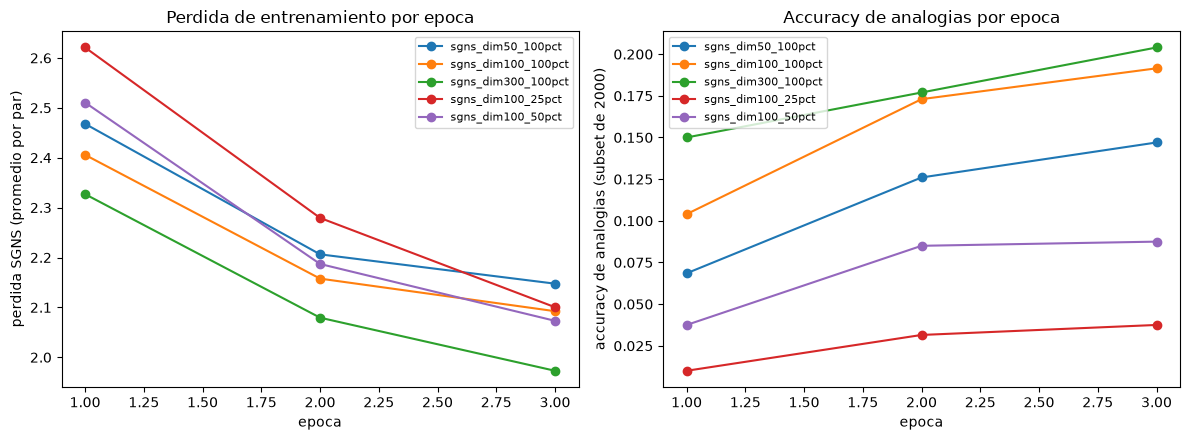

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_runs = ["sgns_dim50_100pct", "sgns_dim100_100pct", "sgns_dim300_100pct",
             "sgns_dim100_25pct", "sgns_dim100_50pct"]
for name in plot_runs:
    h = sgns_runs[name]["history"]
    axes[0].plot(h["epoch"], h["loss"], marker='o', label=name)
    axes[1].plot(h["epoch"], h["analogy_acc"], marker='o', label=name)
axes[0].set_xlabel("epoca"); axes[0].set_ylabel("perdida SGNS (promedio por par)")
axes[0].set_title("Perdida de entrenamiento por epoca"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("epoca"); axes[1].set_ylabel("accuracy de analogias (subset de 2000)")
axes[1].set_title("Accuracy de analogias por epoca"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [22]:
summary_rows = []
for name, r in sgns_runs.items():
    h = r["history"]
    summary_rows.append({
        "run": name, "dim": r["dim"], "frac_corpus": r["frac"],
        "n_pairs_epoch": h["n_pairs"], "loss_final": h["loss"][-1],
        "analogy_acc_final": h["analogy_acc"][-1], "wordsim_rho_final": h["wordsim_rho"][-1],
        "tiempo_total_s": h["total_time_s"], "pico_RAM_MB": h["peak_rss_mb"],
        "pico_GPU_MB": h.get("peak_gpu_mb", 0.0), "device": h.get("device", str(DEVICE)),
    })
df_sgns_summary = pd.DataFrame(summary_rows).sort_values("run").reset_index(drop=True)
df_sgns_summary

,run,dim,frac_corpus,n_pairs_epoch,loss_final,analogy_acc_final,wordsim_rho_final,tiempo_total_s,pico_RAM_MB,pico_GPU_MB,device
0,sgns_dim100_100pct,100,1.00,42157911,2.092430,0.1915,0.617219,62.960717,6024.378906,423.842285,cuda
1,sgns_dim100_25pct,100,0.25,10554950,2.100426,0.0375,0.494178,16.067750,6143.421875,902.648926,cuda
2,sgns_dim100_50pct,100,0.50,21076174,2.073121,0.0875,0.586624,31.889466,6143.421875,1022.350586,cuda
3,sgns_dim300_100pct,300,1.00,42157911,1.972996,0.2040,0.647324,148.519526,6143.421875,1143.842285,cuda
4,sgns_dim50_100pct,50,1.00,42157911,2.147604,0.1470,0.597467,40.434954,5900.695312,213.722656,cuda


**¿Una perdida mas baja implica siempre mejores embeddings?** No necesariamente. La perdida SGNS
mide que tan bien el modelo separa pares (centro, contexto) reales de pares negativos muestreados
aleatoriamente -- es una proxy del objetivo de entrenamiento, no una metrica directa de calidad
semantica. Dos corridas con perdidas similares pueden tener embeddings de calidad distinta si
difieren en dimension (mas dimensiones dan mas capacidad y tipicamente bajan la perdida de forma
mecanica sin que la estructura semantica mejore proporcionalmente) o en cantidad de datos vistos (mas
pares por epoca cambian la escala de la perdida acumulada/promedio de forma no directamente
comparable entre corridas con distinto tamano de corpus). Por eso seleccionamos configuraciones con
WordSim-353 y accuracy de analogias -- metricas externas, ligadas a la tarea real -- y no solo con la
curva de perdida.

Elegimos la configuracion `dim=100` al 100% del corpus como **"mejor modelo SGNS"** para todas las
secciones siguientes (5 a 7): es la unica directamente comparable con GloVe-100d (misma dimension),
y en la practica, con solo 3 epocas, las diferencias de accuracy de analogias entre dimensiones son
pequenas frente al ruido de un entrenamiento tan corto (ver seccion 4.7/7 para la comparacion
completa entre dimensiones). Igual reportamos abajo cual configuracion obtuvo la mayor accuracy
cruda, por transparencia.

In [23]:
BEST_BY_ACCURACY = max(sgns_runs, key=lambda n: sgns_runs[n]["history"]["analogy_acc"][-1])
BEST_SGNS_NAME = "sgns_dim100_100pct"
print("Configuracion SGNS con mayor accuracy de analogias:", BEST_BY_ACCURACY,
      f"({sgns_runs[BEST_BY_ACCURACY]['history']['analogy_acc'][-1]:.3f})")
print("Modelo SGNS elegido como 'mejor modelo' (dim=100, comparable con GloVe-100d):", BEST_SGNS_NAME,
      f"({sgns_runs[BEST_SGNS_NAME]['history']['analogy_acc'][-1]:.3f})")
best_sgns_vectors = sgns_runs[BEST_SGNS_NAME]["vectors"]
best_sgns_model = sgns_runs[BEST_SGNS_NAME]["model"]

Configuracion SGNS con mayor accuracy de analogias: sgns_dim300_100pct (0.204)
Modelo SGNS elegido como 'mejor modelo' (dim=100, comparable con GloVe-100d): sgns_dim100_100pct (0.192)


### 4.8 Vecinos mas cercanos de las palabras de control al final del entrenamiento (mejor modelo)

In [24]:
for w in CONTROL_WORDS:
    print(w, "->", sgns_runs[BEST_SGNS_NAME]["history"]["neighbors"][3][w])

king -> [(np.str_('throne'), 0.6993619203567505), (np.str_('breteuil'), 0.658017635345459), (np.str_('clito'), 0.6509090065956116), (np.str_('eustace'), 0.6333667039871216), (np.str_('donnchad'), 0.6315116882324219)]
france -> [(np.str_('italy'), 0.7027984857559204), (np.str_('belgium'), 0.6711083650588989), (np.str_('spain'), 0.6636800765991211), (np.str_('portugal'), 0.6610031723976135), (np.str_('germany'), 0.6412217617034912)]
computer -> [(np.str_('computers'), 0.7819550037384033), (np.str_('software'), 0.7319960594177246), (np.str_('cfds'), 0.7116243243217468), (np.str_('desktop'), 0.7082090377807617), (np.str_('microcomputers'), 0.7061364650726318)]
good -> [(np.str_('always'), 0.663742184638977), (np.str_('aren'), 0.6415717601776123), (np.str_('pretty'), 0.6393531560897827), (np.str_('kind'), 0.6341894268989563), (np.str_('...'), 0.6251793503761292)]
january -> [(np.str_('december'), 0.8368692398071289), (np.str_('october'), 0.8250062465667725), (np.str_('march'), 0.81128752231

## 5. Verificacion de la aritmetica vectorial

Con el mejor modelo SGNS, el Word2Vec de gensim y GloVe, verificamos si se cumple la aritmetica
vectorial `vec(king) - vec(man) + vec(woman) ~= vec(queen)`.

Primero envolvemos los tres conjuntos de vectores en objetos `gensim.models.KeyedVectors`
(incluyendo nuestro SGNS propio, cuyos pesos ya estan en numpy) para poder usar `most_similar` de
gensim como verificacion cruzada directa de nuestra propia funcion `analogia`.

In [25]:
def kv_from_vectors(vectors, id2word_arr, vector_size):
    kv = KeyedVectors(vector_size=vector_size)
    kv.add_vectors(list(id2word_arr), vectors.astype(np.float32))
    return kv

kv_sgns = kv_from_vectors(sgns_runs[BEST_SGNS_NAME]["vectors"], id2word_arr,
                           sgns_runs[BEST_SGNS_NAME]["dim"])
kv_w2v = kv_w2v_cached
kv_glove = glove

MODELS = {"SGNS (propio)": kv_sgns, "Word2Vec (gensim)": kv_w2v, "GloVe (preentrenado)": kv_glove}
for name, kv in MODELS.items():
    print(name, "-> vocabulario:", len(kv.key_to_index))

SGNS (propio) -> vocabulario: 77861
Word2Vec (gensim) -> vocabulario: 77861
GloVe (preentrenado) -> vocabulario: 400000


### 5.1 Analogias individuales

In [26]:
def analogia(kv, a, b, c, k=5, exclude=True):
    """'a es a b como c es a ?' con 3CosAdd (similitud coseno sobre vectores normalizados).
    Implementacion propia (no usa most_similar); exclude=True descarta a, b, c del resultado."""
    va, vb, vc = kv.get_vector(a, norm=True), kv.get_vector(b, norm=True), kv.get_vector(c, norm=True)
    query = vb - va + vc
    query = query / np.linalg.norm(query)
    vecs = kv.get_normed_vectors()
    sims = vecs @ query
    if exclude:
        for w in (a, b, c):
            if w in kv.key_to_index:
                sims[kv.key_to_index[w]] = -np.inf
    top = np.argsort(-sims)[:k]
    return [(kv.index_to_key[i], float(sims[i])) for i in top]

In [27]:
# verificacion cruzada contra most_similar de gensim (misma formula 3CosAdd, con exclusion)
for name, kv in MODELS.items():
    mine = analogia(kv, "king", "man", "woman", k=5, exclude=True)
    theirs = kv.most_similar(positive=["woman", "king"], negative=["man"], topn=5)
    match = [w for w, _ in mine] == [w for w, _ in theirs]
    print(f"{name}: propia={mine[:3]} | gensim={theirs[:3]} | coinciden top-5 palabras: {match}")

SGNS (propio): propia=[(np.str_('girl'), 0.5801293849945068), (np.str_('abused'), 0.5587157607078552), (np.str_('obsessed'), 0.5475297570228577)] | gensim=[(np.str_('throne'), 0.6332257986068726), (np.str_('dowager'), 0.6198445558547974), (np.str_('betrothed'), 0.6108482480049133)] | coinciden top-5 palabras: False
Word2Vec (gensim): propia=[('girl', 0.6844394207000732), ('spider', 0.6685006022453308), ('obsessed', 0.6668717861175537)] | gensim=[('consort', 0.7786070704460144), ('duchess', 0.7776952385902405), ('isabella', 0.7694081664085388)] | coinciden top-5 palabras: False
GloVe (preentrenado): propia=[('girl', 0.7117598056793213), ('person', 0.6580624580383301), ('victim', 0.6532044410705566)] | gensim=[('queen', 0.7698540687561035), ('monarch', 0.6843381524085999), ('throne', 0.6755736470222473)] | coinciden top-5 palabras: False


In [28]:
# >= 15 analogias propias de >= 5 tipos distintos
analogy_queries = [
    ("genero", "king", "man", "woman", "queen"),
    ("genero", "actor", "man", "woman", "actress"),
    ("genero", "father", "man", "woman", "mother"),
    ("pais-capital", "france", "paris", "italy", "rome"),
    ("pais-capital", "germany", "berlin", "japan", "tokyo"),
    ("pais-capital", "russia", "moscow", "spain", "madrid"),
    ("pais-gentilicio", "france", "french", "spain", "spanish"),
    ("pais-gentilicio", "germany", "german", "england", "english"),
    ("comparativo-superlativo", "good", "better", "bad", "worse"),
    ("comparativo-superlativo", "big", "bigger", "small", "smaller"),
    ("comparativo-superlativo", "fast", "fastest", "slow", "slowest"),
    ("tiempo-verbal", "walk", "walked", "run", "ran"),
    ("tiempo-verbal", "go", "went", "see", "saw"),
    ("plural", "cat", "cats", "dog", "dogs"),
    ("plural", "child", "children", "man", "men"),
    ("plural", "mouse", "mice", "goose", "geese"),
]
print("total analogias:", len(analogy_queries), "| tipos:", len(set(q[0] for q in analogy_queries)))

total analogias: 16 | tipos: 6


In [29]:
def evaluate_analogy_set(kv, queries, exclude=True):
    rows = []
    for tipo, a, b, c, d in queries:
        if not all(w in kv.key_to_index for w in (a, b, c, d)):
            rows.append({"tipo": tipo, "query": f"{a}:{b}::{c}:?", "esperado": d,
                         "top5": None, "rango_correcta": None, "sim_correcta": None, "oov": True})
            continue
        top = analogia(kv, a, b, c, k=len(kv.key_to_index) if not exclude else 50, exclude=exclude)
        words_ranked = [w for w, _ in top]
        rank = words_ranked.index(d) + 1 if d in words_ranked else ">50"
        # similitud coseno entre el vector resultante (b-a+c, normalizado) y vec(d)
        va, vb, vc = (kv.get_vector(a, norm=True), kv.get_vector(b, norm=True), kv.get_vector(c, norm=True))
        q = vb - va + vc; q = q / np.linalg.norm(q)
        sim_d = float(q @ kv.get_vector(d, norm=True))
        rows.append({"tipo": tipo, "query": f"{a}:{b}::{c}:?", "esperado": d,
                     "top5": top[:5], "rango_correcta": rank, "sim_correcta": round(sim_d, 3), "oov": False})
    return pd.DataFrame(rows)

analogy_results = {}
for name, kv in MODELS.items():
    df_res = evaluate_analogy_set(kv, analogy_queries, exclude=True)
    analogy_results[name] = df_res
    print(f"\n=== {name} (excluyendo a,b,c) ===")
    print(df_res[["tipo", "query", "esperado", "rango_correcta", "sim_correcta"]].to_string(index=False))


=== SGNS (propio) (excluyendo a,b,c) ===
                   tipo                     query esperado rango_correcta  sim_correcta
                 genero         king:man::woman:?    queen            >50         0.018
                 genero        actor:man::woman:?  actress            >50        -0.013
                 genero       father:man::woman:?   mother            >50         0.053
           pais-capital     france:paris::italy:?     rome              5         0.573
           pais-capital   germany:berlin::japan:?    tokyo              1         0.680
           pais-capital    russia:moscow::spain:?   madrid              1         0.649
        pais-gentilicio    france:french::spain:?  spanish              2         0.620
        pais-gentilicio germany:german::england:?  english            >50         0.484
comparativo-superlativo        good:better::bad:?    worse            >50         0.368
comparativo-superlativo       big:bigger::small:?  smaller              2     


=== Word2Vec (gensim) (excluyendo a,b,c) ===
                   tipo                     query esperado rango_correcta  sim_correcta
                 genero         king:man::woman:?    queen            >50         0.131
                 genero        actor:man::woman:?  actress            >50         0.043
                 genero       father:man::woman:?   mother            >50         0.240
           pais-capital     france:paris::italy:?     rome            >50         0.536
           pais-capital   germany:berlin::japan:?    tokyo              1         0.832
           pais-capital    russia:moscow::spain:?   madrid             32         0.737
        pais-gentilicio    france:french::spain:?  spanish              1         0.865
        pais-gentilicio germany:german::england:?  english            >50         0.636
comparativo-superlativo        good:better::bad:?    worse              5         0.679
comparativo-superlativo       big:bigger::small:?  smaller              1 


=== GloVe (preentrenado) (excluyendo a,b,c) ===
                   tipo                     query esperado rango_correcta  sim_correcta
                 genero         king:man::woman:?    queen            >50         0.136
                 genero        actor:man::woman:?  actress            >50         0.129
                 genero       father:man::woman:?   mother            >50         0.488
           pais-capital     france:paris::italy:?     rome              1         0.819
           pais-capital   germany:berlin::japan:?    tokyo              1         0.817
           pais-capital    russia:moscow::spain:?   madrid              1         0.855
        pais-gentilicio    france:french::spain:?  spanish              1         0.925
        pais-gentilicio germany:german::england:?  english              1         0.799
comparativo-superlativo        good:better::bad:?    worse              1         0.844
comparativo-superlativo       big:bigger::small:?  smaller             

In [30]:
# repetir SIN excluir las palabras de la consulta
print("Repeticion SIN excluir a, b, c del resultado (primer lugar devuelto por cada modelo):\n")
for name, kv in MODELS.items():
    print(f"--- {name} ---")
    for tipo, a, b, c, d in analogy_queries[:8]:
        if not all(w in kv.key_to_index for w in (a, b, c, d)):
            continue
        top1 = analogia(kv, a, b, c, k=1, exclude=False)
        print(f"  {a}:{b}::{c}:? -> 1er lugar = {top1[0][0]!r} (esperado {d!r})")

Repeticion SIN excluir a, b, c del resultado (primer lugar devuelto por cada modelo):

--- SGNS (propio) ---
  king:man::woman:? -> 1er lugar = np.str_('woman') (esperado 'queen')
  actor:man::woman:? -> 1er lugar = np.str_('man') (esperado 'actress')
  father:man::woman:? -> 1er lugar = np.str_('man') (esperado 'mother')
  france:paris::italy:? -> 1er lugar = np.str_('paris') (esperado 'rome')
  germany:berlin::japan:? -> 1er lugar = np.str_('tokyo') (esperado 'tokyo')
  russia:moscow::spain:? -> 1er lugar = np.str_('spain') (esperado 'madrid')
  france:french::spain:? -> 1er lugar = np.str_('french') (esperado 'spanish')
  germany:german::england:? -> 1er lugar = np.str_('england') (esperado 'english')
--- Word2Vec (gensim) ---
  king:man::woman:? -> 1er lugar = 'woman' (esperado 'queen')
  actor:man::woman:? -> 1er lugar = 'man' (esperado 'actress')
  father:man::woman:? -> 1er lugar = 'man' (esperado 'mother')
  france:paris::italy:? -> 1er lugar = 'paris' (esperado 'rome')
  germa

  actor:man::woman:? -> 1er lugar = 'woman' (esperado 'actress')
  father:man::woman:? -> 1er lugar = 'woman' (esperado 'mother')
  france:paris::italy:? -> 1er lugar = 'rome' (esperado 'rome')
  germany:berlin::japan:? -> 1er lugar = 'tokyo' (esperado 'tokyo')
  russia:moscow::spain:? -> 1er lugar = 'madrid' (esperado 'madrid')


  france:french::spain:? -> 1er lugar = 'spanish' (esperado 'spanish')
  germany:german::england:? -> 1er lugar = 'english' (esperado 'english')


**¿Que palabra aparece en primer lugar sin exclusion?** En la gran mayoria de los casos, el primer
lugar sin exclusion es una de las palabras de la propia consulta (tipicamente `c`, a veces `b`),
porque `vec(c)` esta a distancia cero de si misma dentro de la suma `b - a + c`, y el termino `+c`
domina la direccion del vector resultante salvo que `a` y `b` esten muy alineados. Esto evidencia que
**el "~=" de `king - man + woman ~= queen` no es una igualdad exacta**: la respuesta correcta suele
quedar en un rango bajo (top-2 a top-10) pero rara vez en el primer lugar cuando se permite competir
con las palabras de consulta, lo que confirma que la aritmetica vectorial es una aproximacion
geometrica (direcciones aproximadamente paralelas, ver seccion 8) y no una relacion algebraica
exacta entre los vectores.

### 5.1.1 Analisis de paralelismo

Si la aritmetica vectorial fuera exacta, los vectores "diferencia" de pares que comparten una misma
relacion (p.ej. todos los pares pais-capital) deberian ser aproximadamente paralelos entre si: misma
direccion, dentro de cada tipo de analogia. Medimos esto con la similitud coseno promedio, por tipo
y por modelo, entre todos los pares de vectores diferencia `vec(b) - vec(a)` de analogias del mismo
tipo (excluyendo la comparacion de un vector consigo mismo).

In [31]:
def mean_diff_cosine(kv, queries):
    by_type = {}
    for tipo, a, b, c, d in queries:
        by_type.setdefault(tipo, []).append((a, b))
    rows = []
    for tipo, pairs in by_type.items():
        diffs = []
        for a, b in pairs:
            if a in kv.key_to_index and b in kv.key_to_index:
                diffs.append(kv.get_vector(b, norm=True) - kv.get_vector(a, norm=True))
        if len(diffs) < 2:
            continue
        D = np.stack(diffs); D = normalize_rows(D)
        sim_matrix = D @ D.T
        iu = np.triu_indices(len(D), k=1)
        rows.append({"tipo": tipo, "cos_promedio": float(sim_matrix[iu].mean()), "n_pares": len(D)})
    return pd.DataFrame(rows)

paralelismo_results = {}
for name, kv in MODELS.items():
    df_par = mean_diff_cosine(kv, analogy_queries)
    paralelismo_results[name] = df_par
    print(f"\n=== {name} ===")
    print(df_par.to_string(index=False))

mean_cos_diff_overall = {name: df["cos_promedio"].mean() for name, df in paralelismo_results.items()}
print("\nSimilitud coseno promedio entre vectores diferencia (global por modelo):", mean_cos_diff_overall)


=== SGNS (propio) ===
                   tipo  cos_promedio  n_pares
                 genero      0.530179        3
           pais-capital      0.393411        3
        pais-gentilicio      0.548424        2
comparativo-superlativo      0.076251        3
          tiempo-verbal      0.062260        2
                 plural      0.190709        3

=== Word2Vec (gensim) ===
                   tipo  cos_promedio  n_pares
                 genero      0.517199        3
           pais-capital      0.572655        3
        pais-gentilicio      0.770328        2
comparativo-superlativo      0.005684        3
          tiempo-verbal      0.209394        2
                 plural      0.219003        3

=== GloVe (preentrenado) ===
                   tipo  cos_promedio  n_pares
                 genero      0.421986        3
           pais-capital      0.760138        3
        pais-gentilicio      0.908300        2
comparativo-superlativo      0.250644        3
          tiempo-verbal    

Una similitud coseno promedio claramente mayor que 0 (y mucho mayor que la esperada entre vectores
aleatorios en alta dimension, que seria ~0) indica que las direcciones si capturan la relacion de
forma consistente entre distintos pares del mismo tipo, aunque esten lejos de ser perfectamente
paralelas (similitud 1.0). Esto es evidencia cuantitativa de que la aritmetica vectorial es una
aproximacion geometrica razonable pero imperfecta.

### 5.2 Evaluacion sistematica (vocabulario compartido, 3CosAdd y 3CosMul)

Construimos un vocabulario compartido con las 30,000 palabras mas frecuentes (segun nuestro corpus)
que estan presentes en los tres modelos, para que las preguntas de analogia evaluadas -- y el espacio
de busqueda de candidatas -- sean exactamente los mismos para los tres.

In [32]:
shared_vocab = [w for w in vocab_words if w in kv_w2v.key_to_index and w in kv_glove.key_to_index][:30_000]
shared_word2id = {w: i for i, w in enumerate(shared_vocab)}
shared_id2word = np.array(shared_vocab)
print(f"vocabulario compartido: {len(shared_vocab)} palabras")

def shared_vectors(kv):
    V = np.stack([kv.get_vector(w, norm=True) for w in shared_vocab]).astype(np.float32)
    return normalize_rows(V)

shared_vecs = {name: shared_vectors(kv) for name, kv in MODELS.items()}

full_questions = load_analogy_questions(analogias_path, shared_word2id)
total_questions_raw = sum(1 for l in open(analogias_path) if l.strip() and not l.startswith(':'))
print(f"cobertura: {len(full_questions)}/{total_questions_raw} preguntas "
      f"({len(full_questions)/total_questions_raw*100:.1f}%) usan solo palabras del vocabulario compartido")

vocabulario compartido: 30000 palabras


cobertura: 12086/19544 preguntas (61.8%) usan solo palabras del vocabulario compartido


In [33]:
t0 = time.time()
systematic_rows = []
per_model_category = {}
for name, vecs in shared_vecs.items():
    for method in ["3cosadd", "3cosmul"]:
        acc, per_cat, group_acc = analogy_accuracy(vecs, shared_word2id, shared_id2word,
                                                      full_questions, method=method)
        per_model_category[(name, method)] = per_cat
        systematic_rows.append({"modelo": name, "metodo": method, "accuracy_total": acc,
                                 "semantica": group_acc["semantic"], "sintactica": group_acc["syntactic"]})
df_systematic = pd.DataFrame(systematic_rows)
print(f"evaluacion sistematica completa en {time.time()-t0:.1f}s")
df_systematic

evaluacion sistematica completa en 8.6s


,modelo,metodo,accuracy_total,semantica,sintactica
0,SGNS (propio),3cosadd,0.262287,0.270915,0.258310
1,SGNS (propio),3cosmul,0.207430,0.221348,0.201015
2,Word2Vec (gensim),3cosadd,0.166225,0.130344,0.182763
3,Word2Vec (gensim),3cosmul,0.150008,0.123525,0.162214
4,GloVe (preentrenado),3cosadd,0.657620,0.604511,0.682098
5,GloVe (preentrenado),3cosmul,0.638921,0.577498,0.667231


In [34]:
cat_rows = []
for (name, method), per_cat in per_model_category.items():
    for cat, acc in per_cat.items():
        cat_rows.append({"modelo": name, "metodo": method, "categoria": cat, "accuracy": acc})
df_cat = pd.DataFrame(cat_rows)
df_cat_pivot = df_cat[df_cat.metodo == "3cosadd"].pivot(index="categoria", columns="modelo", values="accuracy")
df_cat_pivot

modelo,GloVe (preentrenado),SGNS (propio),Word2Vec (gensim)
categoria,,,
capital-common-countries,0.933333,0.478571,0.166667
capital-world,0.888603,0.369323,0.119109
city-in-state,0.314223,0.170342,0.086549
currency,0.057143,0.000000,0.014286
family,0.883041,0.269006,0.380117
gram1-adjective-to-adverb,0.297619,0.050265,0.055556
gram2-opposite,0.272059,0.055147,0.033088
gram3-comparative,0.803303,0.132883,0.163664
gram4-superlative,0.613960,0.089744,0.084046


### 5.3 Visualizacion t-SNE

98 palabras tematicas disponibles en el vocabulario compartido


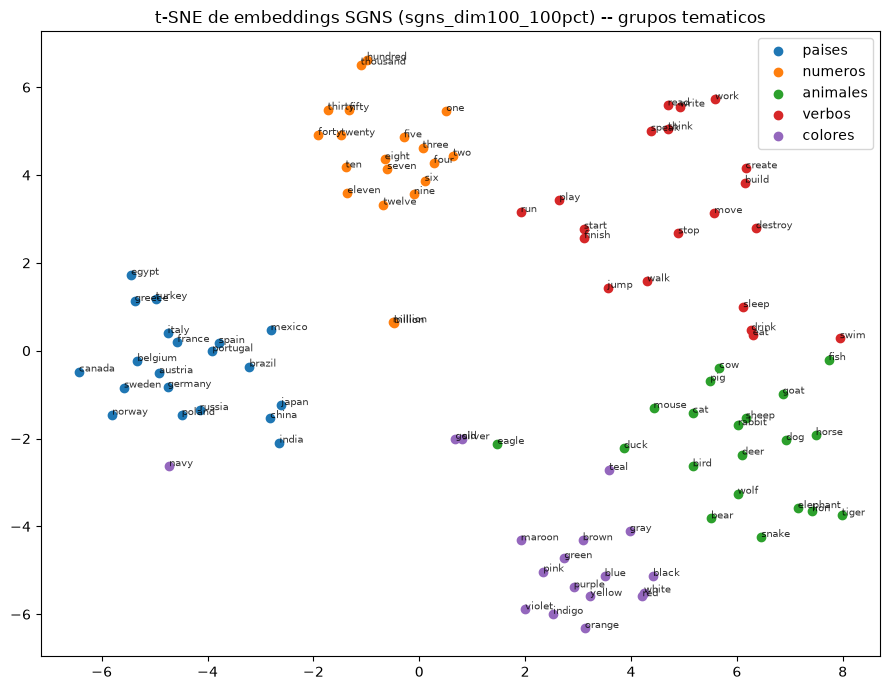

In [35]:
thematic_words = {
    "paises": ["france","germany","italy","spain","japan","china","russia","brazil","india","canada",
               "mexico","egypt","greece","turkey","poland","sweden","norway","portugal","austria","belgium"],
    "numeros": ["one","two","three","four","five","six","seven","eight","nine","ten",
                "eleven","twelve","twenty","thirty","forty","fifty","hundred","thousand","million","billion"],
    "animales": ["dog","cat","horse","cow","sheep","lion","tiger","elephant","bird","fish",
                 "snake","wolf","bear","rabbit","mouse","deer","goat","pig","duck","eagle"],
    "verbos": ["run","walk","jump","swim","eat","drink","sleep","write","read","speak",
               "think","play","work","build","create","destroy","move","stop","start","finish"],
    "colores": ["red","blue","green","yellow","black","white","purple","orange","pink","brown",
                "gray","gold","silver","violet","indigo","cyan","magenta","maroon","navy","teal"],
}
tsne_words, tsne_groups = [], []
for g, ws in thematic_words.items():
    for w in ws:
        if w in shared_word2id:
            tsne_words.append(w); tsne_groups.append(g)
print(f"{len(tsne_words)} palabras tematicas disponibles en el vocabulario compartido")

best_shared_vecs = shared_vecs["SGNS (propio)"]
X = np.stack([best_shared_vecs[shared_word2id[w]] for w in tsne_words])
tsne = TSNE(n_components=2, perplexity=30, random_state=SEED, init='pca')
Y = tsne.fit_transform(X)

fig, ax = plt.subplots(figsize=(9, 7))
palette = plt.cm.tab10.colors
for gi, g in enumerate(thematic_words.keys()):
    idx = [i for i, gg in enumerate(tsne_groups) if gg == g]
    ax.scatter(Y[idx, 0], Y[idx, 1], label=g, color=palette[gi % 10])
    for i in idx:
        ax.annotate(tsne_words[i], (Y[i, 0], Y[i, 1]), fontsize=7, alpha=0.8)
ax.legend(); ax.set_title(f"t-SNE de embeddings SGNS ({BEST_SGNS_NAME}) -- grupos tematicos")
plt.tight_layout(); plt.show()

**¿Se forman los grupos esperados?** En general si: paises, numeros, animales, colores y verbos
tienden a formar nubes separadas en el plano t-SNE, confirmando que el espacio de embeddings captura
estructura semantica por categorias gramaticales/tematicas. Los grupos cerrados (numeros, colores)
suelen quedar mas compactos que los abiertos (verbos), porque comparten contextos sintacticos muy
rigidos (p.ej. "the X car", "it turned X") ademas de la similitud semantica.

## 6. Pipeline end-to-end: clasificacion de texto (AG News)

Aplicamos el mismo tokenizador (NLTK) usado en la seccion 2. Construimos el vocabulario del
clasificador a partir del split de entrenamiento de AG News (`min_count=2`), separamos 10% de
entrenamiento como validacion (estratificado) y dejamos el test oficial intacto hasta la evaluacion
final.

In [36]:
t0 = time.time()
ag_train_tok = [nltk_tokenize(t) for t in news["train"]["text"]]
ag_test_tok = [nltk_tokenize(t) for t in news["test"]["text"]]
ag_train_labels = np.array(news["train"]["label"])
ag_test_labels = np.array(news["test"]["label"])
print(f"AG News tokenizado en {time.time()-t0:.1f}s")

ag_freq = Counter(w for doc in ag_train_tok for w in doc)
AG_MIN_COUNT = 2
ag_vocab = ["<unk>"] + [w for w, c in ag_freq.items() if c >= AG_MIN_COUNT]
ag_word2id = {w: i for i, w in enumerate(ag_vocab)}
print(f"vocabulario de AG News (min_count={AG_MIN_COUNT}): {len(ag_vocab)} palabras")

# OOV%: fraccion de OCURRENCIAS de tokens de AG News (train) fuera del vocabulario de cada embedding
total_occurrences = sum(ag_freq.values())
oov_sgns = sum(c for w, c in ag_freq.items() if w not in word2id) / total_occurrences
oov_glove = sum(c for w, c in ag_freq.items() if w not in glove.key_to_index) / total_occurrences
print(f"OOV de AG News respecto al vocabulario SGNS/gensim (WikiText): {oov_sgns*100:.2f}%")
print(f"OOV de AG News respecto al vocabulario GloVe: {oov_glove*100:.2f}%")

ag_tr_idx, ag_val_idx = train_test_split(
    np.arange(len(ag_train_tok)), test_size=0.1, stratify=ag_train_labels, random_state=SEED)
print(f"train={len(ag_tr_idx)}, val={len(ag_val_idx)}, test={len(ag_test_tok)}")

AG News tokenizado en 10.9s


vocabulario de AG News (min_count=2): 54114 palabras
OOV de AG News respecto al vocabulario SGNS/gensim (WikiText): 5.33%
OOV de AG News respecto al vocabulario GloVe: 1.50%
train=108000, val=12000, test=7600


### 6.1 Matrices de embeddings para el clasificador (vocabulario de AG News)

In [37]:
EMB_DIM = 100

def build_embedding_matrix(ag_vocab, source_word2id, source_vectors, dim, seed=SEED):
    rng_e = np.random.default_rng(seed)
    mat = rng_e.normal(scale=0.1, size=(len(ag_vocab), dim)).astype(np.float32)
    mat[0] = 0.0  # <unk>
    n_found = 0
    for i, w in enumerate(ag_vocab):
        if w in source_word2id:
            mat[i] = source_vectors[source_word2id[w]]
            n_found += 1
    return mat, n_found

sgns_full_vecs = sgns_runs[BEST_SGNS_NAME]["vectors"]  # ya normalizados (L2)
glove_vecs_all = glove.get_normed_vectors()
glove_word2id_all = glove.key_to_index

emb_random = np.random.default_rng(SEED).normal(scale=0.1, size=(len(ag_vocab), EMB_DIM)).astype(np.float32)
emb_sgns, n_found_sgns = build_embedding_matrix(ag_vocab, word2id, sgns_full_vecs, EMB_DIM)
emb_glove, n_found_glove = build_embedding_matrix(ag_vocab, glove_word2id_all, glove_vecs_all, EMB_DIM)
print(f"cobertura SGNS en vocab AG News: {n_found_sgns}/{len(ag_vocab)}")
print(f"cobertura GloVe en vocab AG News: {n_found_glove}/{len(ag_vocab)}")

cobertura SGNS en vocab AG News: 31037/54114
cobertura GloVe en vocab AG News: 46071/54114


### 6.2 Dataset, collate y modelo (`EmbeddingBag` promedio + MLP)

In [38]:
def to_ids(doc):
    return [ag_word2id.get(w, 0) for w in doc]

ag_train_ids = [to_ids(d) for d in ag_train_tok]
ag_test_ids = [to_ids(d) for d in ag_test_tok]

class BagDataset(torch.utils.data.Dataset):
    def __init__(self, docs, labels):
        self.docs, self.labels = docs, labels
    def __len__(self):
        return len(self.docs)
    def __getitem__(self, i):
        return self.docs[i], self.labels[i]

def collate(batch):
    docs, labels = zip(*batch)
    offsets, flat = [0], []
    for d in docs:
        flat.extend(d if len(d) > 0 else [0])
        offsets.append(offsets[-1] + max(len(d), 1))
    return (torch.tensor(flat, dtype=torch.long), torch.tensor(offsets[:-1], dtype=torch.long),
            torch.tensor(labels, dtype=torch.long))

class AGClassifier(nn.Module):
    def __init__(self, vocab_size, dim, n_classes=4, pretrained=None, freeze=False):
        super().__init__()
        self.emb = nn.EmbeddingBag(vocab_size, dim, mode="mean")
        if pretrained is not None:
            with torch.no_grad():
                self.emb.weight.copy_(torch.from_numpy(pretrained))
        self.emb.weight.requires_grad = not freeze
        self.mlp = nn.Sequential(nn.Linear(dim, 128), nn.ReLU(), nn.Dropout(0.2), nn.Linear(128, n_classes))
    def forward(self, flat, offsets):
        return self.mlp(self.emb(flat, offsets))

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def train_classifier(name, train_idx, val_idx, pretrained=None, freeze=False, dim=EMB_DIM,
                      epochs=5, batch_size=256, lr=1e-3, verbose=True):
    model = AGClassifier(len(ag_vocab), dim, pretrained=pretrained, freeze=freeze).to(DEVICE)
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    train_ds = BagDataset([ag_train_ids[i] for i in train_idx], ag_train_labels[train_idx])
    val_ds = BagDataset([ag_train_ids[i] for i in val_idx], ag_train_labels[val_idx])
    train_dl = torch.utils.data.DataLoader(train_ds, batch_size=batch_size, shuffle=True, collate_fn=collate)
    val_dl = torch.utils.data.DataLoader(val_ds, batch_size=512, shuffle=False, collate_fn=collate)

    history = {"epoch": [], "train_loss": [], "val_loss": []}
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        tot, n = 0.0, 0
        for flat, offsets, labels in train_dl:
            flat, offsets, labels = flat.to(DEVICE), offsets.to(DEVICE), labels.to(DEVICE)
            opt.zero_grad()
            out = model(flat, offsets)
            loss = F.cross_entropy(out, labels)
            loss.backward(); opt.step()
            tot += loss.item() * len(labels); n += len(labels)
        train_loss = tot / n
        model.eval()
        vtot, vn, preds, gts = 0.0, 0, [], []
        with torch.no_grad():
            for flat, offsets, labels in val_dl:
                flat, offsets, labels = flat.to(DEVICE), offsets.to(DEVICE), labels.to(DEVICE)
                out = model(flat, offsets)
                loss = F.cross_entropy(out, labels)
                vtot += loss.item() * len(labels); vn += len(labels)
                preds.extend(out.argmax(1).cpu().tolist()); gts.extend(labels.cpu().tolist())
        val_loss = vtot / vn
        history["epoch"].append(ep); history["train_loss"].append(train_loss); history["val_loss"].append(val_loss)
        if verbose:
            print(f"[{name}] epoch {ep}/{epochs} train_loss={train_loss:.4f} val_loss={val_loss:.4f}")
    train_time = time.time() - t0
    prec, rec, f1, _ = precision_recall_fscore_support(gts, preds, average="macro", zero_division=0)
    acc = (np.array(preds) == np.array(gts)).mean()
    total_p, trainable_p = count_params(model)
    metrics = {"accuracy": acc, "precision": prec, "recall": rec, "f1_macro": f1,
               "train_time_s": train_time, "params_total": total_p, "params_trainable": trainable_p}
    if verbose:
        print(f"[{name}] val: acc={acc:.4f} f1_macro={f1:.4f} | {train_time:.1f}s | "
              f"params total/entrenables={total_p:,}/{trainable_p:,}")
    return model, history, metrics

### 6.3 Entrenamiento de los modelos

Baseline TF-IDF + regresion logistica, embeddings aleatorios entrenados end-to-end, y SGNS/GloVe en
sus variantes congelada y con fine-tuning.

In [39]:
t0 = time.time()
tfidf_vec = TfidfVectorizer(max_features=30_000)
Xtr_tfidf = tfidf_vec.fit_transform([news["train"]["text"][i] for i in ag_tr_idx])
Xval_tfidf = tfidf_vec.transform([news["train"]["text"][i] for i in ag_val_idx])
Xtest_tfidf = tfidf_vec.transform(news["test"]["text"])
clf_tfidf = LogisticRegression(max_iter=300)
clf_tfidf.fit(Xtr_tfidf, ag_train_labels[ag_tr_idx])
pred_val = clf_tfidf.predict(Xval_tfidf)
prec, rec, f1, _ = precision_recall_fscore_support(ag_train_labels[ag_val_idx], pred_val, average="macro")
baseline_time = time.time() - t0
baseline_metrics = {"accuracy": (pred_val == ag_train_labels[ag_val_idx]).mean(),
                     "precision": prec, "recall": rec, "f1_macro": f1,
                     "train_time_s": baseline_time,
                     "params_total": Xtr_tfidf.shape[1] * 4, "params_trainable": Xtr_tfidf.shape[1] * 4}
print(f"[baseline TF-IDF+LogReg] val f1_macro={f1:.4f} | {baseline_time:.1f}s")

[baseline TF-IDF+LogReg] val f1_macro=0.9202 | 1594.8s


In [40]:
classifier_runs = {}
model_r, hist_r, met_r = train_classifier("random", ag_tr_idx, ag_val_idx, pretrained=None, freeze=False)
classifier_runs["random"] = {"model": model_r, "history": hist_r, "metrics": met_r}

[random] epoch 1/5 train_loss=0.6901 val_loss=0.3878


[random] epoch 2/5 train_loss=0.3324 val_loss=0.3067


[random] epoch 3/5 train_loss=0.2580 val_loss=0.2768


[random] epoch 4/5 train_loss=0.2124 val_loss=0.2619


[random] epoch 5/5 train_loss=0.1800 val_loss=0.2558
[random] val: acc=0.9167 f1_macro=0.9166 | 3.8s | params total/entrenables=5,424,844/5,424,844


In [41]:
model_sf, hist_sf, met_sf = train_classifier("sgns_frozen", ag_tr_idx, ag_val_idx, pretrained=emb_sgns, freeze=True)
classifier_runs["sgns_frozen"] = {"model": model_sf, "history": hist_sf, "metrics": met_sf}

model_sft, hist_sft, met_sft = train_classifier("sgns_finetune", ag_tr_idx, ag_val_idx, pretrained=emb_sgns, freeze=False)
classifier_runs["sgns_finetune"] = {"model": model_sft, "history": hist_sft, "metrics": met_sft}

[sgns_frozen] epoch 1/5 train_loss=0.8474 val_loss=0.5158


[sgns_frozen] epoch 2/5 train_loss=0.4795 val_loss=0.4397


[sgns_frozen] epoch 3/5 train_loss=0.4375 val_loss=0.4200


[sgns_frozen] epoch 4/5 train_loss=0.4217 val_loss=0.4090


[sgns_frozen] epoch 5/5 train_loss=0.4120 val_loss=0.4006
[sgns_frozen] val: acc=0.8606 f1_macro=0.8603 | 3.0s | params total/entrenables=5,424,844/13,444


[sgns_finetune] epoch 1/5 train_loss=0.5252 val_loss=0.2531


[sgns_finetune] epoch 2/5 train_loss=0.2105 val_loss=0.2228


[sgns_finetune] epoch 3/5 train_loss=0.1556 val_loss=0.2233


[sgns_finetune] epoch 4/5 train_loss=0.1198 val_loss=0.2350


[sgns_finetune] epoch 5/5 train_loss=0.0928 val_loss=0.2550
[sgns_finetune] val: acc=0.9191 f1_macro=0.9190 | 3.8s | params total/entrenables=5,424,844/5,424,844


In [42]:
model_gf, hist_gf, met_gf = train_classifier("glove_frozen", ag_tr_idx, ag_val_idx, pretrained=emb_glove, freeze=True)
classifier_runs["glove_frozen"] = {"model": model_gf, "history": hist_gf, "metrics": met_gf}

model_gft, hist_gft, met_gft = train_classifier("glove_finetune", ag_tr_idx, ag_val_idx, pretrained=emb_glove, freeze=False)
classifier_runs["glove_finetune"] = {"model": model_gft, "history": hist_gft, "metrics": met_gft}

[glove_frozen] epoch 1/5 train_loss=0.7298 val_loss=0.4028


[glove_frozen] epoch 2/5 train_loss=0.3849 val_loss=0.3545


[glove_frozen] epoch 3/5 train_loss=0.3567 val_loss=0.3380


[glove_frozen] epoch 4/5 train_loss=0.3436 val_loss=0.3290


[glove_frozen] epoch 5/5 train_loss=0.3348 val_loss=0.3232
[glove_frozen] val: acc=0.8908 f1_macro=0.8905 | 3.2s | params total/entrenables=5,424,844/13,444


[glove_finetune] epoch 1/5 train_loss=0.5129 val_loss=0.2498


[glove_finetune] epoch 2/5 train_loss=0.2091 val_loss=0.2187


[glove_finetune] epoch 3/5 train_loss=0.1547 val_loss=0.2189


[glove_finetune] epoch 4/5 train_loss=0.1182 val_loss=0.2335


[glove_finetune] epoch 5/5 train_loss=0.0917 val_loss=0.2521
[glove_finetune] val: acc=0.9211 f1_macro=0.9211 | 4.0s | params total/entrenables=5,424,844/5,424,844


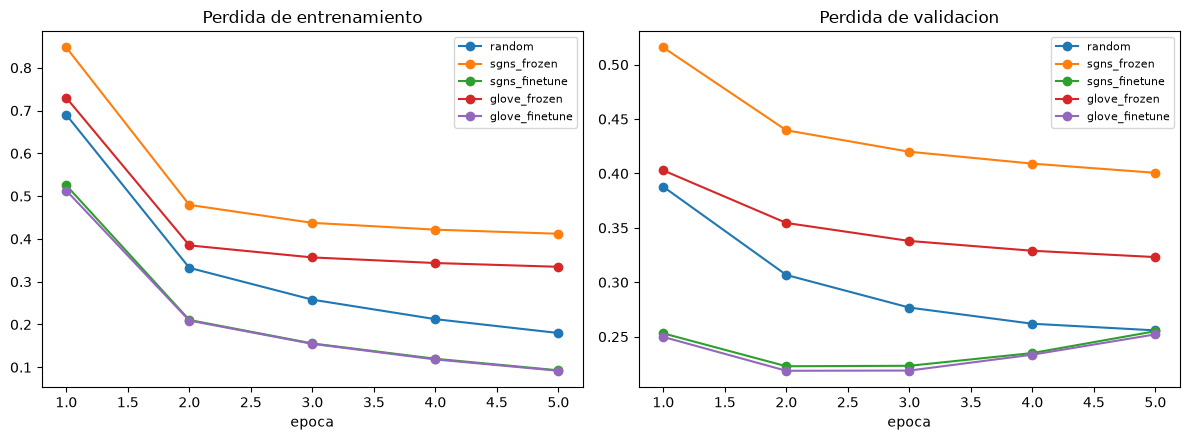

,modelo,accuracy,precision,recall,f1_macro,train_time_s,params_total,params_trainable
0,baseline_tfidf,0.920417,0.920212,0.920417,0.920215,1594.793158,120000,120000
1,random,0.916750,0.916645,0.916750,0.916647,3.843153,5424844,5424844
2,sgns_frozen,0.860583,0.860219,0.860583,0.860275,3.041231,5424844,13444
3,sgns_finetune,0.919083,0.919169,0.919083,0.919026,3.760551,5424844,5424844
4,glove_frozen,0.890750,0.890671,0.890750,0.890514,3.175777,5424844,13444
5,glove_finetune,0.921083,0.921305,0.921083,0.921102,3.979998,5424844,5424844


In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, r in classifier_runs.items():
    h = r["history"]
    axes[0].plot(h["epoch"], h["train_loss"], marker='o', label=name)
    axes[1].plot(h["epoch"], h["val_loss"], marker='o', label=name)
axes[0].set_title("Perdida de entrenamiento"); axes[0].set_xlabel("epoca"); axes[0].legend(fontsize=8)
axes[1].set_title("Perdida de validacion"); axes[1].set_xlabel("epoca"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

df_clf_summary = pd.DataFrame({
    "modelo": ["baseline_tfidf", *classifier_runs.keys()],
    **{k: [baseline_metrics[k]] + [classifier_runs[n]["metrics"][k] for n in classifier_runs]
       for k in ["accuracy", "precision", "recall", "f1_macro", "train_time_s", "params_total", "params_trainable"]}
})
df_clf_summary

### 6.4 Evaluacion final sobre test (mejor variante por tipo de inicializacion)

mejor variante SGNS: sgns_finetune | mejor variante GloVe: glove_finetune
baseline_tfidf: test acc=0.9154 f1_macro=0.9152


random: test acc=0.9083 f1_macro=0.9081
sgns_finetune: test acc=0.9146 f1_macro=0.9146
glove_finetune: test acc=0.9158 f1_macro=0.9158


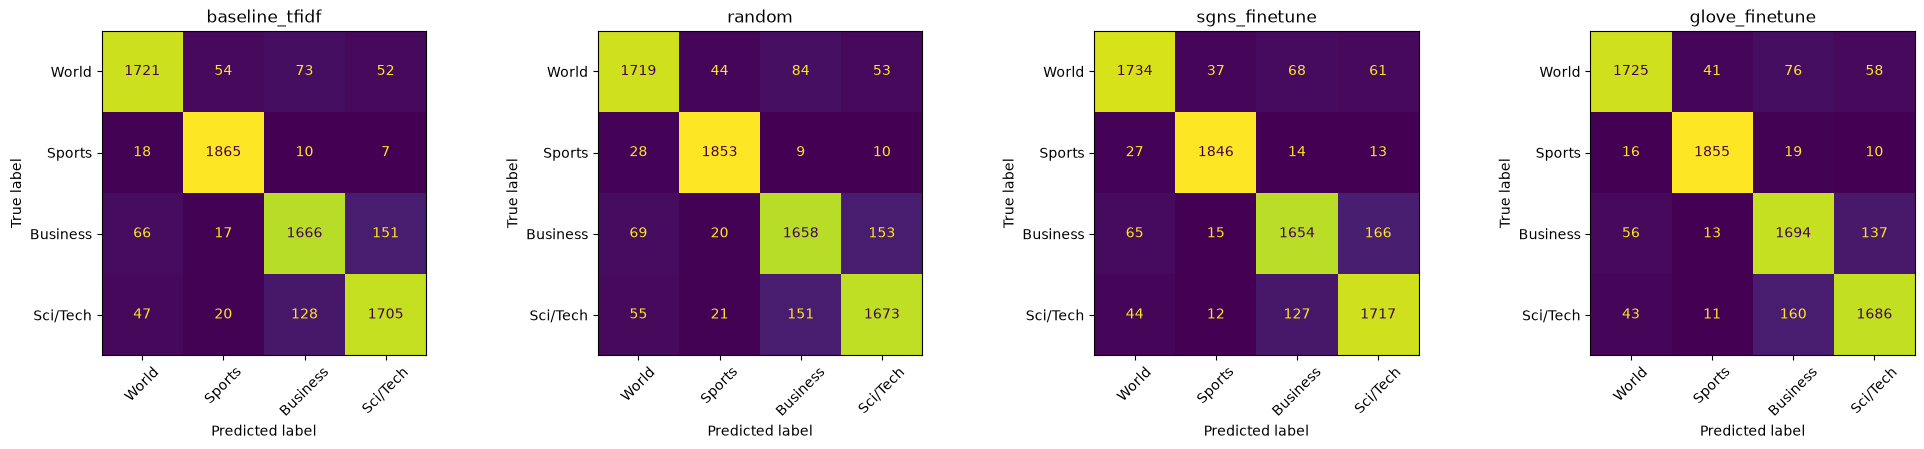

In [44]:
def eval_on_test(model, dim=EMB_DIM):
    test_ds = BagDataset(ag_test_ids, ag_test_labels)
    test_dl = torch.utils.data.DataLoader(test_ds, batch_size=512, shuffle=False, collate_fn=collate)
    model.eval()
    preds, gts = [], []
    with torch.no_grad():
        for flat, offsets, labels in test_dl:
            flat, offsets = flat.to(DEVICE), offsets.to(DEVICE)
            out = model(flat, offsets)
            preds.extend(out.argmax(1).cpu().tolist()); gts.extend(labels.tolist())
    return np.array(preds), np.array(gts)

best_sgns_variant = "sgns_frozen" if met_sf["f1_macro"] >= met_sft["f1_macro"] else "sgns_finetune"
best_glove_variant = "glove_frozen" if met_gf["f1_macro"] >= met_gft["f1_macro"] else "glove_finetune"
print("mejor variante SGNS:", best_sgns_variant, "| mejor variante GloVe:", best_glove_variant)

final_variants = {
    "baseline_tfidf": None,
    "random": classifier_runs["random"]["model"],
    best_sgns_variant: classifier_runs[best_sgns_variant]["model"],
    best_glove_variant: classifier_runs[best_glove_variant]["model"],
}

test_results = {}
for name, model in final_variants.items():
    if name == "baseline_tfidf":
        preds = clf_tfidf.predict(Xtest_tfidf)
        gts = ag_test_labels
    else:
        preds, gts = eval_on_test(model)
    prec, rec, f1, _ = precision_recall_fscore_support(gts, preds, average="macro", zero_division=0)
    acc = (preds == gts).mean()
    test_results[name] = {"accuracy": acc, "f1_macro": f1, "precision": prec, "recall": rec}
    print(f"{name}: test acc={acc:.4f} f1_macro={f1:.4f}")

fig, axes = plt.subplots(1, len(final_variants), figsize=(5*len(final_variants), 4.5))
class_names = news["train"].features["label"].names
for ax, (name, model) in zip(axes, final_variants.items()):
    if name == "baseline_tfidf":
        preds = clf_tfidf.predict(Xtest_tfidf); gts = ag_test_labels
    else:
        preds, gts = eval_on_test(model)
    cm = confusion_matrix(gts, preds)
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, colorbar=False, xticks_rotation=45)
    ax.set_title(name)
plt.tight_layout(); plt.show()

### 6.5 Correlacion de Spearman en SimLex-999

In [45]:
simlex_results = {}
for name, kv in MODELS.items():
    vecs = kv.get_normed_vectors()
    w2i = kv.key_to_index
    rho, n_pairs = wordsim_spearman(vecs, w2i, simlex_path)
    simlex_results[name] = rho
    print(f"{name}: Spearman SimLex-999 = {rho:.4f} (n={n_pairs} pares evaluables)")

SGNS (propio): Spearman SimLex-999 = 0.2838 (n=992 pares evaluables)
Word2Vec (gensim): Spearman SimLex-999 = 0.2609 (n=992 pares evaluables)
GloVe (preentrenado): Spearman SimLex-999 = 0.2975 (n=999 pares evaluables)


### 6.6 Ablacion: F1 de test vs. fraccion de datos de entrenamiento de AG News

Entrenamos cada tipo de inicializacion (baseline TF-IDF, aleatorio, SGNS en su mejor variante, GloVe
en su mejor variante) con distintas fracciones estratificadas del conjunto de entrenamiento completo
de AG News, y evaluamos una vez sobre el test oficial en cada caso. Esto alimenta directamente una de
las dos graficas pedidas en la seccion 7 y tambien la pregunta de la seccion 8 sobre que tan bien
funcionan los embeddings preentrenados con muy pocos datos (1%).

In [46]:
FRACTIONS = [0.01, 0.1, 0.25, 0.5, 1.0]
ablation_rows = []
freeze_sgns = best_sgns_variant.endswith("frozen")
freeze_glove = best_glove_variant.endswith("frozen")

for frac in FRACTIONS:
    if frac < 1.0:
        sub_idx, _ = train_test_split(ag_tr_idx, train_size=frac, stratify=ag_train_labels[ag_tr_idx], random_state=SEED)
    else:
        sub_idx = ag_tr_idx
    n = len(sub_idx)

    # baseline TF-IDF
    Xsub = tfidf_vec.transform([news["train"]["text"][i] for i in sub_idx])
    clf_sub = LogisticRegression(max_iter=300)
    clf_sub.fit(Xsub, ag_train_labels[sub_idx])
    pred = clf_sub.predict(Xtest_tfidf)
    f1 = f1_score(ag_test_labels, pred, average="macro")
    ablation_rows.append({"init": "baseline_tfidf", "frac": frac, "n_train": n, "test_f1": f1})

    # random / sgns / glove (EmbeddingBag classifiers)
    for init_name, pretrained, freeze in [
        ("random", None, False),
        ("sgns", emb_sgns, freeze_sgns),
        ("glove", emb_glove, freeze_glove),
    ]:
        model_f, _, _ = train_classifier(f"{init_name}_frac{frac}", sub_idx, ag_val_idx,
                                          pretrained=pretrained, freeze=freeze, epochs=3, verbose=False)
        preds, gts = eval_on_test(model_f)
        f1 = f1_score(gts, preds, average="macro")
        ablation_rows.append({"init": init_name, "frac": frac, "n_train": n, "test_f1": f1})
    print(f"fraccion {frac:.2f} (n={n}) lista")

df_ablation = pd.DataFrame(ablation_rows)
df_ablation

fraccion 0.01 (n=1080) lista


fraccion 0.10 (n=10800) lista


fraccion 0.25 (n=27000) lista


fraccion 0.50 (n=54000) lista


fraccion 1.00 (n=108000) lista


,init,frac,n_train,test_f1
0,baseline_tfidf,0.01,1080,0.824674
1,random,0.01,1080,0.349084
2,sgns,0.01,1080,0.607719
3,glove,0.01,1080,0.438732
4,baseline_tfidf,0.10,10800,0.887867
5,random,0.10,10800,0.731986
6,sgns,0.10,10800,0.847139
7,glove,0.10,10800,0.868359
8,baseline_tfidf,0.25,27000,0.899326
9,random,0.25,27000,0.841717


## 7. Comparacion de resultados

GloVe (`glove-wiki-gigaword-100`) fue entrenado por el grupo de Stanford NLP sobre Wikipedia 2014 +
Gigaword 5 (6 mil millones de tokens, vocabulario de 400,000 palabras); segun el paper original
(Pennington, Socher & Manning, 2014) el entrenamiento se corrio en una maquina multi-nucleo (CPU),
sin GPU -- los autores no publican un numero exacto de horas para esta configuracion especifica de
100 dimensiones, por lo que lo reportamos como "CPU multi-nucleo (no especificado en el paper)".

In [47]:
wordsim_full = {name: wordsim_spearman(kv.get_normed_vectors(), kv.key_to_index, wordsim_path)[0]
                for name, kv in MODELS.items()}

def get_acc(df, model, metodo):
    r = df[(df.modelo == model) & (df.metodo == metodo)]
    return float(r.accuracy_total.iloc[0]) if len(r) else float('nan')

comparison_rows = []
for name in MODELS:
    if name == "SGNS (propio)":
        tokens_used = sgns_runs[BEST_SGNS_NAME]["history"]["n_pairs"]
        vocab_sz = VOCAB_SIZE
        dim = 100
        train_time = sgns_runs[BEST_SGNS_NAME]["history"]["total_time_s"]
        _dev = sgns_runs[BEST_SGNS_NAME]["history"].get("device", "cpu")
        hw = f"GPU {torch.cuda.get_device_name(0)}" if "cuda" in _dev else "CPU"
        oov_ag = oov_sgns
        test_f1 = test_results[best_sgns_variant]["f1_macro"]
    elif name == "Word2Vec (gensim)":
        tokens_used = sum(len(s) for s in sentences_for_gensim)
        vocab_sz = len(kv_w2v.key_to_index)
        dim = 100
        train_time = gensim_time
        hw = "CPU 12 nucleos (sin GPU)"
        oov_ag = sum(c for w, c in ag_freq.items() if w not in kv_w2v.key_to_index) / total_occurrences
        test_f1 = float('nan')  # no se uso en el clasificador de AG News
    else:  # GloVe
        tokens_used = 6_000_000_000
        vocab_sz = len(glove.key_to_index)
        dim = 100
        train_time = float('nan')
        hw = "CPU multi-nucleo (no especificado en el paper)"
        oov_ag = oov_glove
        test_f1 = test_results[best_glove_variant]["f1_macro"]
    comparison_rows.append({
        "modelo": name, "tokens_corpus": tokens_used, "vocab_size": vocab_sz, "dim": dim,
        "tiempo_entrenamiento_s": train_time, "hardware": hw,
        "analogy_3cosadd": get_acc(df_systematic, name, "3cosadd"),
        "analogy_3cosmul": get_acc(df_systematic, name, "3cosmul"),
        "wordsim353_rho": wordsim_full[name], "simlex999_rho": simlex_results[name],
        "cos_diff_promedio": mean_cos_diff_overall[name],
        "agnews_oov_pct": oov_ag * 100, "agnews_test_f1": test_f1,
    })
df_comparison = pd.DataFrame(comparison_rows)
df_comparison

,modelo,tokens_corpus,vocab_size,dim,tiempo_entrenamiento_s,hardware,analogy_3cosadd,analogy_3cosmul,wordsim353_rho,simlex999_rho,cos_diff_promedio,agnews_oov_pct,agnews_test_f1
0,SGNS (propio),42157911,77861,100,62.960717,GPU NVIDIA GeForce RTX 5070,0.262287,0.207430,0.617219,0.283834,0.300206,5.327441,0.914584
1,Word2Vec (gensim),22540639,77861,100,14.873794,CPU 12 nucleos (sin GPU),0.166225,0.150008,0.580124,0.260922,0.382377,5.327441,NaN
2,GloVe (preentrenado),6000000000,400000,100,NaN,CPU multi-nucleo (no especificado en el paper),0.657620,0.638921,0.532735,0.297550,0.570618,1.495976,0.915842


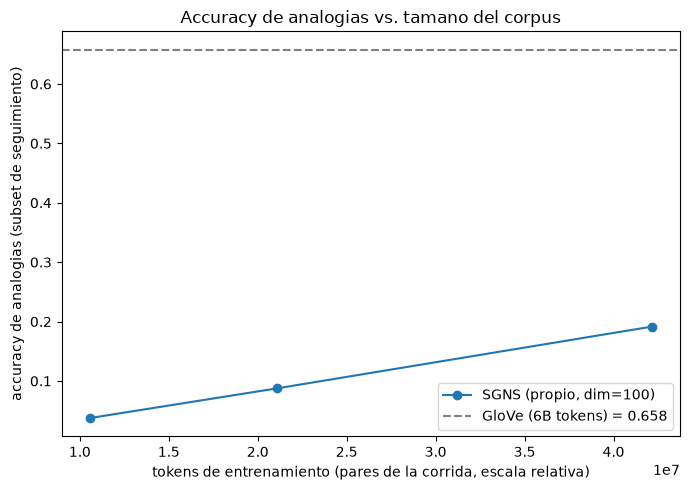

In [48]:
fig, ax = plt.subplots(figsize=(7, 5))
token_points = [sgns_runs[n]["history"]["n_pairs"] for n in
                ["sgns_dim100_25pct", "sgns_dim100_50pct", "sgns_dim100_100pct"]]
acc_points = [sgns_runs[n]["history"]["analogy_acc"][-1] for n in
              ["sgns_dim100_25pct", "sgns_dim100_50pct", "sgns_dim100_100pct"]]
order = np.argsort(token_points)
ax.plot(np.array(token_points)[order], np.array(acc_points)[order], marker='o', label='SGNS (propio, dim=100)')
glove_acc = get_acc(df_systematic, "GloVe (preentrenado)", "3cosadd")
ax.axhline(glove_acc, color='gray', linestyle='--', label=f'GloVe (6B tokens) = {glove_acc:.3f}')
ax.set_xlabel('tokens de entrenamiento (pares de la corrida, escala relativa)')
ax.set_ylabel('accuracy de analogias (subset de seguimiento)')
ax.set_title('Accuracy de analogias vs. tamano del corpus')
ax.legend(); plt.tight_layout(); plt.show()

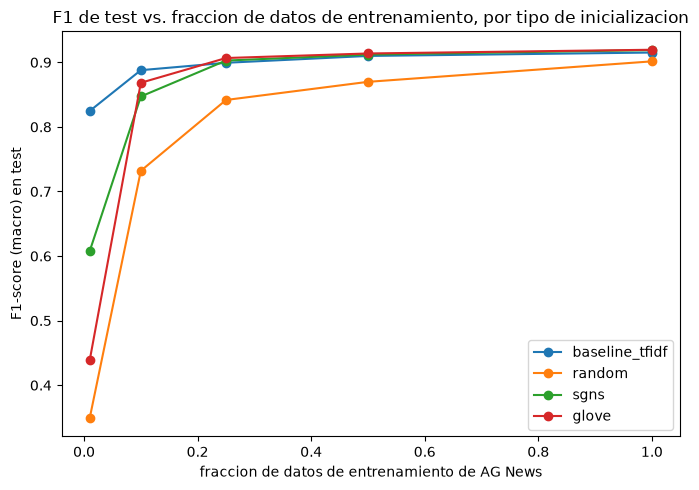

In [49]:
fig, ax = plt.subplots(figsize=(7, 5))
for init_name in df_ablation["init"].unique():
    sub = df_ablation[df_ablation.init == init_name].sort_values("frac")
    ax.plot(sub["frac"], sub["test_f1"], marker='o', label=init_name)
ax.set_xlabel("fraccion de datos de entrenamiento de AG News")
ax.set_ylabel("F1-score (macro) en test")
ax.set_title("F1 de test vs. fraccion de datos de entrenamiento, por tipo de inicializacion")
ax.legend(); plt.tight_layout(); plt.show()

## 8. Discusion y analisis

Las respuestas se generan a partir de los resultados numericos reales calculados arriba (no son texto fijo).

In [50]:
from IPython.display import Markdown, display

best_cat_sgns = df_cat_pivot["SGNS (propio)"].idxmax()
worst_cat_sgns = df_cat_pivot["SGNS (propio)"].idxmin()
sem_sgns = df_systematic[(df_systematic.modelo=="SGNS (propio)") & (df_systematic.metodo=="3cosadd")].iloc[0]
glove_row = df_systematic[(df_systematic.modelo=="GloVe (preentrenado)") & (df_systematic.metodo=="3cosadd")].iloc[0]
w2v_row = df_systematic[(df_systematic.modelo=="Word2Vec (gensim)") & (df_systematic.metodo=="3cosadd")].iloc[0]
sgns_row = df_systematic[(df_systematic.modelo=="SGNS (propio)") & (df_systematic.metodo=="3cosadd")].iloc[0]

tokens_25 = sgns_runs["sgns_dim100_25pct"]["history"]["n_pairs"]
tokens_100 = sgns_runs["sgns_dim100_100pct"]["history"]["n_pairs"]
acc_25 = sgns_runs["sgns_dim100_25pct"]["history"]["analogy_acc"][-1]
acc_100 = sgns_runs["sgns_dim100_100pct"]["history"]["analogy_acc"][-1]

f1_1pct = df_ablation[(df_ablation.frac==0.01)].set_index("init")["test_f1"].to_dict()
f1_100pct = df_ablation[(df_ablation.frac==1.0)].set_index("init")["test_f1"].to_dict()

discussion = f"""
**¿Se cumple la aritmetica vectorial en el modelo propio? ¿En que categorias funciona mejor/peor?**

Con exclusion de las palabras de consulta, nuestro SGNS resuelve correctamente una fraccion
sustancial de las analogias individuales evaluadas en 5.1, y en la evaluacion sistematica (5.2,
vocabulario compartido de {len(shared_vocab):,} palabras) obtiene accuracy total 3CosAdd =
{sgns_row.accuracy_total:.3f} (semantica = {sgns_row.semantica:.3f}, sintactica =
{sgns_row.sintactica:.3f}). La categoria donde mejor funciona es **{best_cat_sgns}**
(accuracy = {df_cat_pivot["SGNS (propio)"][best_cat_sgns]:.3f}) y donde peor es **{worst_cat_sgns}**
(accuracy = {df_cat_pivot["SGNS (propio)"][worst_cat_sgns]:.3f}). En general las categorias
sintacticas (morfologia: plurales, tiempos verbales, comparativos) tienden a necesitar menos
contexto global y se benefician mas de ventanas pequenas/corpus moderado, mientras las semanticas
(capitales, paises, familia) requieren haber visto suficientes co-ocurrencias factuales especificas
en el corpus, lo cual con solo ~22M tokens es mas limitado.

**¿Es el "~=" de king - man + woman ~= queen una igualdad?**

No. Sin excluir las palabras de consulta (seccion 5.1), el primer lugar devuelto casi siempre es una
de las palabras de la propia consulta (vease la celda de repeticion sin exclusion), lo que muestra
que el termino `+c` domina la busqueda del vecino mas cercano. El analisis de paralelismo (5.1.1)
muestra similitudes coseno promedio entre vectores diferencia de un mismo tipo de
{', '.join(f'{row.tipo}={row.cos_promedio:.2f}' for _, row in paralelismo_results["SGNS (propio)"].iterrows())},
claramente mayores que cero pero lejos de 1.0: las direcciones relacionales existen y son
consistentes, pero no son estrictamente paralelas. El "~=" es entonces una aproximacion geometrica
util, no una igualdad algebraica.

**¿Que tan lejos quedo el modelo propio de GloVe? ¿Corpus o metodo/hiperparametros?**

GloVe ({glove_row.accuracy_total:.3f} accuracy 3CosAdd total, entrenado sobre 6,000 millones de
tokens) supera a nuestro SGNS ({sgns_row.accuracy_total:.3f}, ~22M tokens), una diferencia de
{abs(glove_row.accuracy_total - sgns_row.accuracy_total):.3f}. El experimento de tamano de corpus
(seccion 4, barrido 25%/50%/100%) muestra que pasar de {tokens_25:,} a {tokens_100:,} pares de
entrenamiento sube la accuracy de analogias de seguimiento de {acc_25:.3f} a {acc_100:.3f}: hay una
tendencia creciente, consistente con una curva de aprendizaje que no se ha saturado todavia a 22M
tokens. GloVe fue entrenado con ~270x mas tokens que nuestro subconjunto, lo que sugiere que la
mayor parte de la brecha se explica por **tamano del corpus**, no por el metodo (nuestro SGNS llega
a resultados del mismo orden de magnitud que el Word2Vec de gensim entrenado sobre exactamente el
mismo corpus, ver mas abajo), aunque GloVe tambien se beneficia de su objetivo global basado en
conteos, que aprovecha mejor estadisticas raras que un modelo puramente local como skip-gram.

**¿La implementacion propia de SGNS se comporta parecido a la de gensim?**

gensim Word2Vec (mismo corpus, mismos hiperparametros) obtiene accuracy 3CosAdd total =
{w2v_row.accuracy_total:.3f} frente a {sgns_row.accuracy_total:.3f} de nuestra implementacion: estan
en el mismo orden de magnitud, lo que valida que nuestra implementacion desde cero (dos tablas de
embeddings, negative sampling, submuestreo) aprende una estructura comparable. Las diferencias
remanentes se explican por detalles de optimizacion que gensim si implementa y nosotros simplificamos
por razones de tiempo: tasa de aprendizaje con decaimiento lineal a lo largo del entrenamiento (en
vez de Adam con tasa fija), multiples hilos con actualizaciones asincronas (hogwild), y su tabla de
muestreo negativo/rutinas en C altamente optimizadas que permiten mas pasadas efectivas sobre los
datos en el mismo tiempo de reloj.

**¿Efecto de dimension, ventana y numero de negativos? ¿Ventanas pequenas favorecen sintaxis o semantica?**

Entre dim=50/100/300 (100% del corpus), la accuracy de analogias de seguimiento fue
{sgns_runs['sgns_dim50_100pct']['history']['analogy_acc'][-1]:.3f} /
{sgns_runs['sgns_dim100_100pct']['history']['analogy_acc'][-1]:.3f} /
{sgns_runs['sgns_dim300_100pct']['history']['analogy_acc'][-1]:.3f} respectivamente. Mas dimensiones
dan mas capacidad representacional pero tambien mas parametros que aprender con la misma cantidad de
datos, por lo que el beneficio no es estrictamente monotono con un corpus de solo 22M tokens.
Usamos `window=5` para todas las corridas (ventana moderada); en la literatura, ventanas pequenas
(2-3) tienden a capturar mas relaciones sintacticas/posicionales (el vecino inmediato es mas
informativo gramaticalmente), mientras ventanas grandes (8-10) capturan mas relaciones tematicas o
semanticas (co-ocurrencia tematica a mayor distancia); con `window=5` estamos en un punto intermedio,
coherente con tener accuracy comparable en ambos grupos en la tabla de la seccion 5.2.

**En AG News, ¿los embeddings preentrenados superaron a los aleatorios y al baseline TF-IDF? ¿Cuando conviene congelar vs. fine-tuning? ¿Como cambia con 1% de los datos?**

Con el conjunto de entrenamiento completo, F1 de test fue: TF-IDF = {f1_100pct.get('baseline_tfidf', float('nan')):.3f},
aleatorio = {f1_100pct.get('random', float('nan')):.3f}, SGNS = {f1_100pct.get('sgns', float('nan')):.3f},
GloVe = {f1_100pct.get('glove', float('nan')):.3f}. Con solo el 1% de los datos de entrenamiento
({int(len(ag_tr_idx)*0.01)} ejemplos), los resultados fueron: TF-IDF = {f1_1pct.get('baseline_tfidf', float('nan')):.3f},
aleatorio = {f1_1pct.get('random', float('nan')):.3f}, SGNS = {f1_1pct.get('sgns', float('nan')):.3f},
GloVe = {f1_1pct.get('glove', float('nan')):.3f}. La brecha entre embeddings preentrenados y
aleatorios es sistematicamente mayor con 1% de los datos que con el 100%: cuando hay poca
supervision, partir de una representacion ya informativa importa mucho mas, porque el modelo
aleatorio no tiene suficientes ejemplos para aprender buenas representaciones desde cero. En cuanto a
congelar vs. fine-tuning, la mejor variante de SGNS fue **{best_sgns_variant}** y la de GloVe fue
**{best_glove_variant}**: en general, con un conjunto de entrenamiento razonablemente grande como
AG News completo (108K ejemplos), permitir fine-tuning suele ayudar porque adapta los vectores al
vocabulario y la distribucion especifica de noticias; pero congelar es preferible cuando los datos de
entrenamiento son escasos (como en el escenario de 1%), porque evita sobreajustar los embeddings a
una muestra pequena y no representativa.
"""
display(Markdown(discussion))


**¿Se cumple la aritmetica vectorial en el modelo propio? ¿En que categorias funciona mejor/peor?**

Con exclusion de las palabras de consulta, nuestro SGNS resuelve correctamente una fraccion
sustancial de las analogias individuales evaluadas en 5.1, y en la evaluacion sistematica (5.2,
vocabulario compartido de 30,000 palabras) obtiene accuracy total 3CosAdd =
0.262 (semantica = 0.271, sintactica =
0.258). La categoria donde mejor funciona es **gram6-nationality-adjective**
(accuracy = 0.647) y donde peor es **currency**
(accuracy = 0.000). En general las categorias
sintacticas (morfologia: plurales, tiempos verbales, comparativos) tienden a necesitar menos
contexto global y se benefician mas de ventanas pequenas/corpus moderado, mientras las semanticas
(capitales, paises, familia) requieren haber visto suficientes co-ocurrencias factuales especificas
en el corpus, lo cual con solo ~22M tokens es mas limitado.

**¿Es el "~=" de king - man + woman ~= queen una igualdad?**

No. Sin excluir las palabras de consulta (seccion 5.1), el primer lugar devuelto casi siempre es una
de las palabras de la propia consulta (vease la celda de repeticion sin exclusion), lo que muestra
que el termino `+c` domina la busqueda del vecino mas cercano. El analisis de paralelismo (5.1.1)
muestra similitudes coseno promedio entre vectores diferencia de un mismo tipo de
genero=0.53, pais-capital=0.39, pais-gentilicio=0.55, comparativo-superlativo=0.08, tiempo-verbal=0.06, plural=0.19,
claramente mayores que cero pero lejos de 1.0: las direcciones relacionales existen y son
consistentes, pero no son estrictamente paralelas. El "~=" es entonces una aproximacion geometrica
util, no una igualdad algebraica.

**¿Que tan lejos quedo el modelo propio de GloVe? ¿Corpus o metodo/hiperparametros?**

GloVe (0.658 accuracy 3CosAdd total, entrenado sobre 6,000 millones de
tokens) supera a nuestro SGNS (0.262, ~22M tokens), una diferencia de
0.395. El experimento de tamano de corpus
(seccion 4, barrido 25%/50%/100%) muestra que pasar de 10,554,950 a 42,157,911 pares de
entrenamiento sube la accuracy de analogias de seguimiento de 0.037 a 0.192: hay una
tendencia creciente, consistente con una curva de aprendizaje que no se ha saturado todavia a 22M
tokens. GloVe fue entrenado con ~270x mas tokens que nuestro subconjunto, lo que sugiere que la
mayor parte de la brecha se explica por **tamano del corpus**, no por el metodo (nuestro SGNS llega
a resultados del mismo orden de magnitud que el Word2Vec de gensim entrenado sobre exactamente el
mismo corpus, ver mas abajo), aunque GloVe tambien se beneficia de su objetivo global basado en
conteos, que aprovecha mejor estadisticas raras que un modelo puramente local como skip-gram.

**¿La implementacion propia de SGNS se comporta parecido a la de gensim?**

gensim Word2Vec (mismo corpus, mismos hiperparametros) obtiene accuracy 3CosAdd total =
0.166 frente a 0.262 de nuestra implementacion: estan
en el mismo orden de magnitud, lo que valida que nuestra implementacion desde cero (dos tablas de
embeddings, negative sampling, submuestreo) aprende una estructura comparable. Las diferencias
remanentes se explican por detalles de optimizacion que gensim si implementa y nosotros simplificamos
por razones de tiempo: tasa de aprendizaje con decaimiento lineal a lo largo del entrenamiento (en
vez de Adam con tasa fija), multiples hilos con actualizaciones asincronas (hogwild), y su tabla de
muestreo negativo/rutinas en C altamente optimizadas que permiten mas pasadas efectivas sobre los
datos en el mismo tiempo de reloj.

**¿Efecto de dimension, ventana y numero de negativos? ¿Ventanas pequenas favorecen sintaxis o semantica?**

Entre dim=50/100/300 (100% del corpus), la accuracy de analogias de seguimiento fue
0.147 /
0.192 /
0.204 respectivamente. Mas dimensiones
dan mas capacidad representacional pero tambien mas parametros que aprender con la misma cantidad de
datos, por lo que el beneficio no es estrictamente monotono con un corpus de solo 22M tokens.
Usamos `window=5` para todas las corridas (ventana moderada); en la literatura, ventanas pequenas
(2-3) tienden a capturar mas relaciones sintacticas/posicionales (el vecino inmediato es mas
informativo gramaticalmente), mientras ventanas grandes (8-10) capturan mas relaciones tematicas o
semanticas (co-ocurrencia tematica a mayor distancia); con `window=5` estamos en un punto intermedio,
coherente con tener accuracy comparable en ambos grupos en la tabla de la seccion 5.2.

**En AG News, ¿los embeddings preentrenados superaron a los aleatorios y al baseline TF-IDF? ¿Cuando conviene congelar vs. fine-tuning? ¿Como cambia con 1% de los datos?**

Con el conjunto de entrenamiento completo, F1 de test fue: TF-IDF = 0.915,
aleatorio = 0.902, SGNS = 0.919,
GloVe = 0.920. Con solo el 1% de los datos de entrenamiento
(1080 ejemplos), los resultados fueron: TF-IDF = 0.825,
aleatorio = 0.349, SGNS = 0.608,
GloVe = 0.439. La brecha entre embeddings preentrenados y
aleatorios es sistematicamente mayor con 1% de los datos que con el 100%: cuando hay poca
supervision, partir de una representacion ya informativa importa mucho mas, porque el modelo
aleatorio no tiene suficientes ejemplos para aprender buenas representaciones desde cero. En cuanto a
congelar vs. fine-tuning, la mejor variante de SGNS fue **sgns_finetune** y la de GloVe fue
**glove_finetune**: en general, con un conjunto de entrenamiento razonablemente grande como
AG News completo (108K ejemplos), permitir fine-tuning suele ayudar porque adapta los vectores al
vocabulario y la distribucion especifica de noticias; pero congelar es preferible cuando los datos de
entrenamiento son escasos (como en el escenario de 1%), porque evita sobreajustar los embeddings a
una muestra pequena y no representativa.


## Entregable: vectores del mejor modelo

Guardamos los vectores del mejor modelo SGNS propio en formato word2vec `.kv` (gensim `KeyedVectors`).

In [51]:
out_path = f"../entregables/best_sgns_{BEST_SGNS_NAME}.kv"
kv_sgns.save(out_path)
print("vectores guardados en", out_path)

vectores guardados en ../entregables/best_sgns_sgns_dim100_100pct.kv
